# **Zomato Restaurant Cluster ML Submission**    -



##### **Project Type -** Unsupervised
##### **Contribution -** Individual
##### **Team Member 1 -** Abinash Kanungo

# **Project Summary -**


## About

Zomato is an Indian food delivery and restaurant discovery platform that was started in 2008. It connects users with restaurants across India by listing menus, prices, reviews, and delivery options. India has a large and varied food scene, with thousands of restaurants spread across every city and state. As more people choose to eat out or order in, the restaurant industry keeps growing, and so does the data around it.

---

## Purpose of This Project

This project uses Zomato data to understand patterns in the Indian restaurant industry, specifically across different cities. The goal is to uncover very useful information to understand how customers feel about the restaurants they visit, and to group restaurants into meaningful segments based on what they offer and how they are priced.

---

## The Two Core Parts

### 1. Sentiment Analysis
The first part looks at customer reviews to figure out whether their experience was positive, negative, or somewhere in between. By doing this at scale, it becomes possible to spot trends — which types of restaurants get the most recognitions / preferences , which cities have more satisfied diners, and where restaurants are consistently falling short.

### 2. Restaurants Clustering
The second part groups restaurants that share similar traits together. Things like cuisine type, average cost, location, and ratings. This helps identify what kinds of restaurants are common in certain areas, which price points are most popular, and where there might be gaps in the market.

---

## How Does This Help?

| Stakeholder | Benefit |
|-------------|---------|
| **Customers** | Easier to find a good restaurant nearby that fits their budget and preference |
| **For Zomato** | Highlights areas where the platform can improve, penetrate underserved cities, look into low-rated cuisine types, or weak review coverage |

---

## Tools and Libraries Used

- **Pandas** — data handling and organization
- **NumPy** — numerical calculations in dataset features
- **Matplotlib & Seaborn** — charts and visual summaries
- **Scikit-learn** — building clustering models

---

## Project Flow

1. Understand the dataset and problem
2. Clean the data, handle missing values and outliers
3. Explore the data through charts and summaries
4. Apply at least two clustering algorithms
5. Describe each cluster in simple, actionable terms
6. Draw conclusions and present findings visually

---

## Key Takeaway

This project takes raw Zomato restaurant data, understanding it through analysis and grouping, and turns it into clear insights useful for everyday users looking for a good meal experience and for the business to understand where it stands and where it can grow.

# **GitHub Link -**

### https://github.com/abinashkng/Zomato_Restaurant_Clustering_Unsupervised_AI-ML_Model.git

# **Problem Statement**

India's restaurant industry is growing rapidly, with thousands of dining options spread across cities offering diverse cuisines, price ranges, and experiences. With so many choices available, it becomes difficult for customers to find the right restaurant and equally difficult for a platform like Zomato to understand what is working and what is not.

The data collected from Zomato contains a wealth of information such as restaurant locations, cuisine types, cost, ratings, and customer reviews but as in raw form, this data does not tell a clear story. There is no structured way to group restaurants by similarity, no clear picture of how customers actually feel about their experiences, and no easy method to identify which segments of the market are thriving and which are being overlooked.

This project aims to solve that by doing two things:
* First, it analyses customer reviews to determine the overall sentiment — whether feedback is positive, negative, or neutral — and uses that to draw conclusions about customer satisfaction across different restaurants and cities.
* Second, it applies unsupervised machine learning techniques to cluster restaurants into distinct groups based on features like cuisine, cost, and location, so that meaningful patterns can be identified without any prior labelling.

The outcome of this analysis is intended to help customers make better dining decisions and help Zomato understand its restaurant landscape more clearly — identifying strong performing segments, gaps in coverage, and areas that need attention.

## ***1. Know the Data***

### Import Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.stats import pearsonr, ttest_ind
import numpy as np
import pickle
import warnings
warnings.filterwarnings('ignore')

### Dataset Loading

In [ ]:
# Load datasets
metadata = pd.read_csv(r'https://drive.google.com/uc?export=download&id=1I9rt3mgST7nPFrX6q1nQZP11r8f6QQz7')
reviews = pd.read_csv(r'https://drive.google.com/uc?export=download&id=19jCibKaHbgIy5sFqN0TIeO9nmaRlJG51')
print('='*35)

# Check data shape
print("Metadata shape:", metadata.shape)
print("Reviews shape:", reviews.shape)
print('='*35)

# Merge datasets on Restaurant column, Rename column, drop duplicate Restaurant_Name Column
df = pd.merge(metadata, reviews, left_on='Name', right_on='Restaurant', how='inner')
df= df.drop(columns=['Restaurant'])
df = df.rename(columns={'Name': 'Restaurant_Name'})
# Display merged result
print("Merged DataFrame shape:", df.shape)
print("Columns:", df.columns)
print('='*35)
print(df.sample(n=5).head())
print('='*35)

Metadata shape: (105, 6)
Reviews shape: (10000, 7)
Merged DataFrame shape: (10000, 12)
Columns: Index(['Restaurant_Name', 'Links', 'Cost', 'Collections', 'Cuisines',
       'Timings', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time',
       'Pictures'],
      dtype='object')
                              Restaurant_Name  \
9626                        Hyderabadi Daawat   
4205                             Karachi Cafe   
5144                Hitech Bawarchi Food Zone   
6533  Komatose - Holiday Inn Express & Suites   
1692                      NorFest - The Dhaba   

                                                  Links   Cost  \
9626  https://www.zomato.com/hyderabad/hyderabadi-da...    600   
4205  https://www.zomato.com/hyderabad/karachi-cafe-...    600   
5144  https://www.zomato.com/hyderabad/hitech-bawarc...    500   
6533  https://www.zomato.com/hyderabad/komatose-holi...  1,500   
1692  https://www.zomato.com/hyderabad/norfest-the-d...    550   

                              

**Explanation**:
I mentioned the exact dataset file paths in the cell to point the cloud or local machine storage locations as specified in the snippet. This will allow the datasets to load successfully.
Also i renamed the 'Name' column to 'Restaurant_name' and drop the 'Restaurant' column from `df`, as to avoid duplicacy of columns.





### Dataset First View

In [ ]:
# Dataset First Look
print('='*50)
print(metadata.head())
print('='*50)
print(reviews.head())
print('='*50)
print(df.head())
print('='*50)

                             Name  \
0                 Beyond Flavours   
1                        Paradise   
2                        Flechazo   
3  Shah Ghouse Hotel & Restaurant   
4      Over The Moon Brew Company   

                                               Links   Cost  \
0  https://www.zomato.com/hyderabad/beyond-flavou...    800   
1  https://www.zomato.com/hyderabad/paradise-gach...    800   
2  https://www.zomato.com/hyderabad/flechazo-gach...  1,300   
3  https://www.zomato.com/hyderabad/shah-ghouse-h...    800   
4  https://www.zomato.com/hyderabad/over-the-moon...  1,200   

                                         Collections  \
0  Food Hygiene Rated Restaurants in Hyderabad, C...   
1                                Hyderabad's Hottest   
2                 Great Buffets, Hyderabad's Hottest   
3                             Late Night Restaurants   
4  Best Bars & Pubs, Food Hygiene Rated Restauran...   

                                            Cuisines  \
0  Ch

### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count
print("Metadata DataFrame shape:", metadata.shape)
print("Reviews DataFrame shape:", reviews.shape)
print("Merged DataFrame shape:", df.shape)

Metadata DataFrame shape: (105, 6)
Reviews DataFrame shape: (10000, 7)
Merged DataFrame shape: (10000, 12)


**Explanation :**
The step is to display the row and column counts of `metadata` and `reviews` dataframes, and then merge them into a new DataFrame named `df` and its row and column counts and all 3 of them mentioned above.

- The dataset consists of 10,000 entries (rows) and 13 columns after merging `df1` and `df2`.


### Dataset Information

In [ ]:
print("DATASET INFORMATION")
print("="*50)
df.info()  # Display column info
print("="*50)
print(f"""\nData Types:\n
{df.dtypes}""") # Display column types

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Restaurant_Name  10000 non-null  object
 1   Links            10000 non-null  object
 2   Cost             10000 non-null  object
 3   Collections      5000 non-null   object
 4   Cuisines         10000 non-null  object
 5   Timings          9900 non-null   object
 6   Reviewer         9962 non-null   object
 7   Review           9955 non-null   object
 8   Rating           9962 non-null   object
 9   Metadata         9962 non-null   object
 10  Time             9962 non-null   object
 11  Pictures         10000 non-null  int64 
dtypes: int64(1), object(11)
memory usage: 937.6+ KB

Data Types:

Restaurant_Name    object
Links              object
Cost               object
Collections        object
Cuisines           object
Timings            object
Reviewer           

**Explanation :**
- **Data Types:** Most columns are of object type, indicating they contain strings or mixed data types, which will require further cleaning and encoding for analysis. `Pictures` is an integer type.


#### Duplicate Values

In [ ]:
# Check for duplicate rows

dup_df1 = metadata.duplicated().sum()
dup_df2 = reviews.duplicated().sum()
dup_merged = df.duplicated().sum()

print(f"""Duplicates Present:

df1: {dup_df1},
df2: {dup_df2},
merged: {dup_merged}""")

# Remove duplicates
if dup_merged > 0:
    df = df.drop_duplicates(keep='first')
    print(f"Removed {dup_merged} duplicates. New shape: {df.shape}")

Duplicates Present:

df1: 0,
df2: 36,
merged: 36
Removed 36 duplicates. New shape: (9964, 12)


**Explanation**:
In this step, i counted duplicate values in `metadata`, `reviews`, and the merged `df`.

- After renaming 'Name' to 'Restaurant_name' and dropping 'Restaurant', the `df` DataFrame has 12 columns.
- `df1` (Restaurant names and Metadata) had 105 entries(rows) and 6 columns. `df2` (Restaurant reviews) had 10,000 entries(rows) and 7 columns.
- There are no duplicate rows in the initial `df1` dataset, but `df2` has 36 duplicate rows, which carried over to the merged `df`.

#### Missing Values/Null Values

In [ ]:
# Analyze missing values
missing = df.isnull().sum()
missing_cols = missing[missing > 0].sort_values(ascending=False)
missing_percent = (missing[missing > 0] / (df).shape[0]) * 100
print("Missing values per column:")
print('=='*10)
print(missing_cols)
print('=='*10)
print(f"Total missing: {missing.sum()}")
print('=='*10)
print(f"Total records: {len(df)}")
print('=='*10)
print("Percentage missing:")
print('=='*10)
print(missing_percent)

Missing values per column:
Collections    5000
Timings         100
Review            9
Reviewer          2
Rating            2
Metadata          2
Time              2
dtype: int64
Total missing: 5117
Total records: 9964
Percentage missing:
Collections    50.180650
Timings         1.003613
Reviewer        0.020072
Review          0.090325
Rating          0.020072
Metadata        0.020072
Time            0.020072
dtype: float64


**Explanation:**
This cell counts missing values for each column if present in the dataset and what are those and how many are there, like in `metadata`, `review`, and the merged `df`.

**Explanation**:
This step is took to get a summary of the merged DataFrame `df` including data types and non-null values.



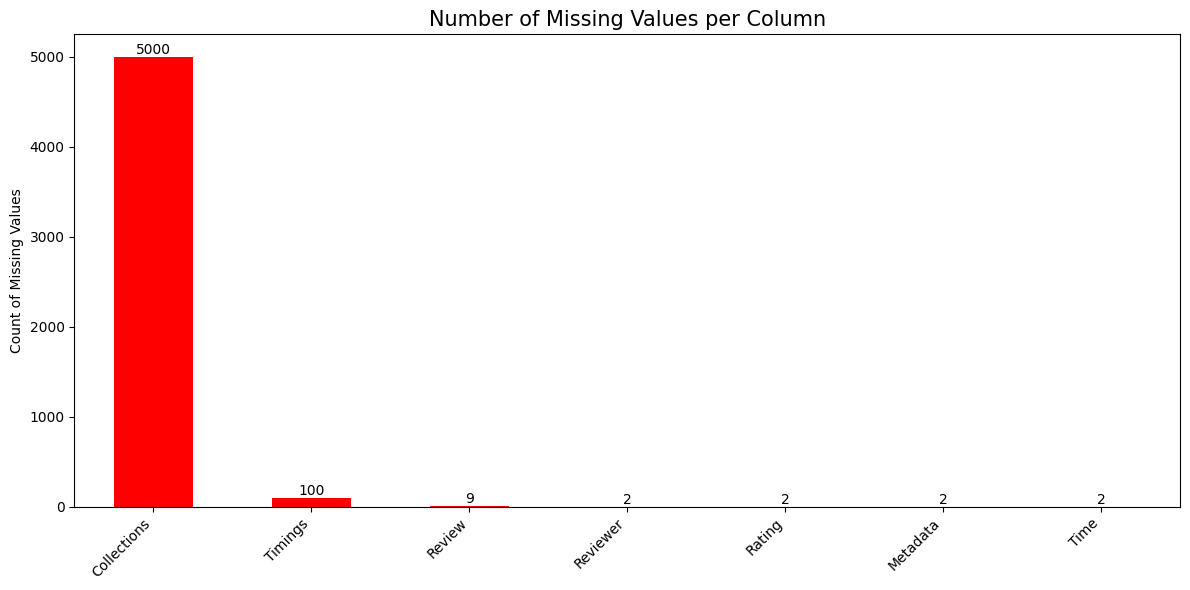

In [ ]:
# Visualizing the missing values
# Calculate missing values
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

# Create bar plot
plt.figure(figsize=(12, 6))
ax = missing.plot(kind='bar', color='red')

# Add value labels
for i, v in enumerate(missing):
    ax.text(i, v + 0.1, str(v), ha='center', va='bottom')

plt.title('Number of Missing Values per Column', fontsize=15)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Count of Missing Values')
plt.tight_layout()
plt.show()

**Explanation**:
This step i took to visualize the missing values in `df` in form of a bar chart showing the count of missing values per column.

**Missing Values:**
    - `Collections` has a significant number of missing values (5000 out of 10000), indicating that half of the entries lack collection information. This is the column with the most missing values.
    - `Timings` has 100 missing values.
    - `Reviewer`, `Review`, `Rating`, `Metadata`, and `Time` have relatively small numbers of missing values (below 10).

### What did you know about your dataset?

The dataset contains merged restaurant metadata + review data with thousands of entries. It includes both numerical features (Cost, Rating, Pictures) and categorical features (Collections, Cuisines, Timings). Duplicates were removed for data integrity.

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns
df.columns.to_list()

['Restaurant_Name',
 'Links',
 'Cost',
 'Collections',
 'Cuisines',
 'Timings',
 'Reviewer',
 'Review',
 'Rating',
 'Metadata',
 'Time',
 'Pictures']

**Explanation**:
This list all column names present inside `df`dataset.


In [ ]:
# Dataset Describe
df.describe(include='all')

,Restaurant_Name,Links,Cost,Collections,Cuisines,Timings,Reviewer,Review,Rating,Metadata,Time,Pictures
count,9964,9964,9964,4964,9964,9864,9962,9955,9962,9962,9962,9964.000000
unique,100,100,28,42,89,74,7446,9364,10,2477,9782,NaN
top,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,500,Food Hygiene Rated Restaurants in Hyderabad,"North Indian, Chinese",11 AM to 11 PM,Parijat Ray,good,5,1 Review,7/29/2018 20:34,NaN
freq,100,100,1200,378,400,500,13,237,3832,919,3,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.751305
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.574626
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000


**Explanation**:
This is to get descriptive statistics of whole dataset features.


### Variables Description

* Restaurant name has 9,964 rows, 100 unique names, and text type. Beyond Flavours appears most often.
* Links has 9,964 rows, 100 unique Zomato links, and text type. Beyond Flavours link appears most often.
* Cost has 9,964 rows, 28 unique values, and text type with commas. 500Rs. is most common sold items value.
* Collections has 4,964 rows, 50% missing values, 42 unique tags, and text type. Food Hygiene Rated Restaurants is top.
* Cuisines has 9,964 rows, 89 unique combinations, and text type. North Indian and Chinese are most frequent.
* Timings has 9,864 rows, 100 missing values, 74 unique formats, and text type. 11 AM to 11 PM is most common.
* Reviewer has 9,962 rows, 2 missing values, 7,446 unique names, and text type. Parijat Ray is most active.
* Review has 9,955 rows, 9 missing values, 9,364 unique text blocks, and text type. Good is the top review word.
* Rating has 9,962 rows, 2 missing values, 10 unique text scores, and text type. Score of 5 is most frequent.
* Metadata has 9,962 rows, 2 missing values, 2,477 unique user metric strings, and text type.
* Time has 9,962 rows, 2 missing values, 9,782 unique post timestamps, and text type.
* Pictures has 9,964 rows, 36 unique counts, and is already stored as integer type.

### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable.
for i in df.columns:
    print(i, ":", df[i].nunique(),"unique values are present")
    print("\n" + "Top 5 Unique Values:")
    print(df[i].unique()[0:5].tolist())
    print('=='*20 + "\n")

Restaurant_Name : 100 unique values are present

Top 5 Unique Values:
['Beyond Flavours', 'Paradise', 'Flechazo', 'Shah Ghouse Hotel & Restaurant', 'Over The Moon Brew Company']

Links : 100 unique values are present

Top 5 Unique Values:
['https://www.zomato.com/hyderabad/beyond-flavours-gachibowli', 'https://www.zomato.com/hyderabad/paradise-gachibowli', 'https://www.zomato.com/hyderabad/flechazo-gachibowli', 'https://www.zomato.com/hyderabad/shah-ghouse-hotel-restaurant-gachibowli', 'https://www.zomato.com/hyderabad/over-the-moon-brew-company-gachibowli']

Cost : 28 unique values are present

Top 5 Unique Values:
['800', '1,300', '1,200', '1,500', '500']

Collections : 42 unique values are present

Top 5 Unique Values:
['Food Hygiene Rated Restaurants in Hyderabad, Corporate Favorites, Great Buffets, Top-Rated, Gold Curated, Live Sports Screenings', "Hyderabad's Hottest", "Great Buffets, Hyderabad's Hottest", 'Late Night Restaurants', "Best Bars & Pubs, Food Hygiene Rated Restaurant

**Explanation**:
The step is to check and print unique values for each variable in `df`.

- **Unique Values Insights (preliminary):**
    - `Restaurant_name` has 100 unique values, suggesting 100 distinct restaurants, each appearing multiple times (likely due to multiple reviews).
    - `Links` also has 100 unique values, corresponding to each unique restaurant.
    - `Cost` has 28 unique values, but they are currently stored as objects and contain commas (e.g., '1,300'), requiring conversion to numeric type.
    - `Collections` has 42 unique categories, but half are missing. This column will need careful handling.
    - `Cuisines` has 89 unique combinations, indicating a wide variety of food options.
    - `Timings` has 74 unique values, suggesting varied operating hours.
    - `Reviewer`, `Review`, `Rating`, `Metadata`, and `Time` show a high number of unique values, as expected for review-related data.
    - `Rating` has 10 unique values, but it's an object type, suggesting it might contain non-numeric characters or be parsed incorrectly (e.g., '1', '3.5', '5', '1.5'). This will need to be converted to a numeric type for quantitative analysis.
    - `Pictures` has 36 unique values and is already an integer type, representing the number of pictures.

## 3. ***Data Wrangling***

### Data Wrangling

In [ ]:
# 1. Clean Cost column (remove commas and convert to float)
df['Cost'] = df['Cost'].astype(str).str.replace(',', '').astype(float)

# 2. Convert Rating to numeric
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')

# 3. Fill missing values in remaining columns
categorical_cols = ['Timings', 'Reviewer', 'Metadata', 'Time']
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# 4. Nulls are handled in Rating, Review column if exists further
df['Rating'] = df['Rating'].fillna(df['Rating'].median())
df['Review'] = df['Review'].fillna('No Review')

In [ ]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OrdinalEncoder
import numpy as np

# Only encode categorical columns
encode_cols = ['Collections', 'Cuisines']

# If a new category appears during transform, if NaN then gets -1 instead of crash
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

df_encoded = df.copy()
df_encoded[encode_cols] = encoder.fit_transform(df[encode_cols])

# Add Cost separately as numeric for KNN distance calculation
knn_cols = encode_cols + ['Cost'] # Cost also influences the Collection
imputer = KNNImputer(n_neighbors=5)
df_encoded[knn_cols] = imputer.fit_transform(df_encoded[knn_cols])

# Inverse transform the encoded categorical columns
df_encoded[encode_cols] = np.round(df_encoded[encode_cols])
df[encode_cols] = encoder.inverse_transform(df_encoded[encode_cols])

# Check Cost data type for original state
print(df['Cost'].dtype)
print("Missing in Collections", df['Collections'].isnull().sum())

float64
Missing in Collections 0


In [ ]:
# Verify data quality
print("Data shape:", df.shape)
print("Data Info:")
print(df.info())
print("Missing values:", df.isnull().sum())

Data shape: (9964, 12)
Data Info:
<class 'pandas.core.frame.DataFrame'>
Index: 9964 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Restaurant_Name  9964 non-null   object 
 1   Links            9964 non-null   object 
 2   Cost             9964 non-null   float64
 3   Collections      9964 non-null   object 
 4   Cuisines         9964 non-null   object 
 5   Timings          9964 non-null   object 
 6   Reviewer         9964 non-null   object 
 7   Review           9964 non-null   object 
 8   Rating           9964 non-null   float64
 9   Metadata         9964 non-null   object 
 10  Time             9964 non-null   object 
 11  Pictures         9964 non-null   int64  
dtypes: float64(2), int64(1), object(9)
memory usage: 1012.0+ KB
None
Missing values: Restaurant_Name    0
Links              0
Cost               0
Collections        0
Cuisines           0
Timings            0
Reviewer

### What all manipulations have you done and insights you found?

**Manipulations Performed:**

**Step 1 : (Type Conversion)**

Stripped commas from Cost to convert text based currency into floats and marked invalid texts as NaN.

**Step 2 : (Simple Imputation)**

Replaced missing values in Timings, Reviewer, Metadata, and Time columns using their modes, also filled empty 'Review' clolumn values with a 'No Review' placeholder and Rating null values with the median.

**Step 3 : (KNN Imputation)**

Resolved 5,000 empty values in Collections by numerical encoding and running a 5 nearest neighbors using KNN algorithm. This predicted missing categories using matching price values and Cuisines before decoding to original value.

---

**Key Insights:**
- Data quality checked by validated the final dataset with 9,964 clean records.
- Cost and Rating now numeric, ready for further statistical analysis.
- Dataset fully cleaned and no nulls, correct types, ready for EDA and clustering

## ***4. Data Visualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 : Restaurants Ratings Distribution (Univariate Analysis)

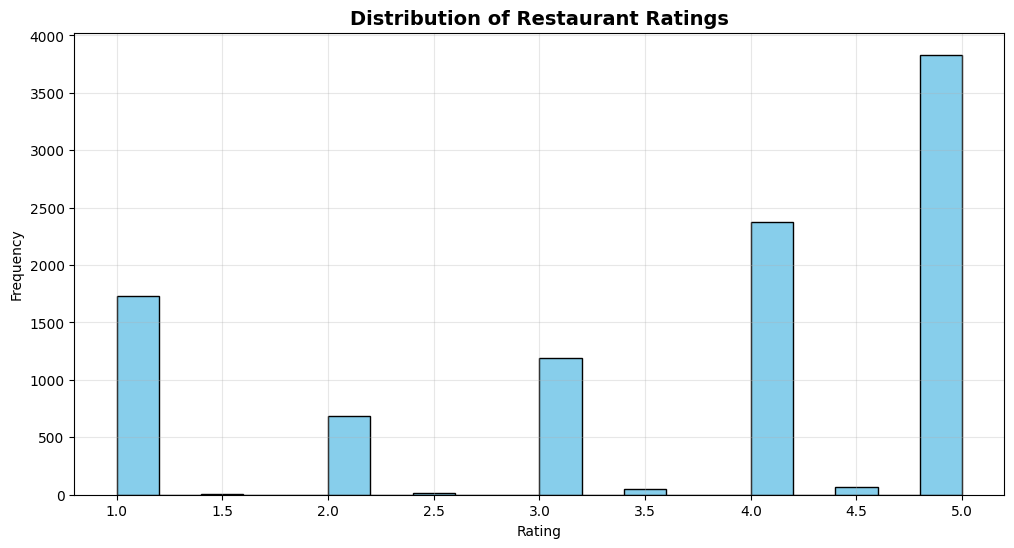

In [ ]:
# Restaurants Ratings Distribution
plt.figure(figsize=(12, 6))
df['Rating'].hist(bins=20, edgecolor='black', color='skyblue')
plt.title('Distribution of Restaurant Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()

##### 1. Why did i pick the specific chart?

Histogram is ideal here for visualizing Rating distribution because:
* Shows frequency distribution of continuous variable
* Reveals customer satisfaction patterns
* Identifies rating clusters and central tendencies
* Detects outliers and distribution shape

##### 2. What is/are the insight(s) found from the chart?

**Key Insights:**
* Shape: Two peaks are there, one at 1.0 and one at 5.0. Most restaurants got either very low or very high ratings. Middle ratings are rare.
* Positive ratings: About 76% of restaurants are rated 3.0 or above. Most restaurants are doing well.
* Low ratings are not rare: Around 1,750 restaurants got a 1.0 rating. That is 17% of the data.
* The 5.0 spike is because of people usually rate only when they are very happy or very angry. So extreme scores are common, not because every restaurant is perfect, but because average experiences go unrated.
* Business takeaway: In the platform Zomato has a split, a large group of highly rated restaurants and a significant group of poorly rated ones. The middle is thin.

##### 3. Will the gained insights help creating a positive business impact?

Yes, the insights create direct business impact.

- Restaurants rated 4.0 and above should get more visibility in search and homepage because they are already proven and convert new users faster.
- Around 1,750 restaurants have a 1.0 rating, which is too large in numbers to ignore. Zomato needs a plan to either improve them, or penalize them before they damage user trust.
- The ranking algorithm should not treat a 5.0 restaurant with 3 reviews the same as a 4.2 restaurant with 300 reviews, because volume of reviews matters equally the score itself.
- The spike at 5.0 is most likely rating bias, so Zomato ranking should personalised and recommendation of restaurants should be done using each user's past behaviour rather than relying on platform-wide ranking averages that are skewed towards extreme scores.
- 3.0 ranked restaurants and below 3.0 rank holding restaurants should be enrolled in a structured support & guidance program covering presentation, menu quality, ad campaigns and services before any visibility penalty is applied.

#### Chart - 2 :  Distribution of Restaurant Costs (Univariate Analysis)

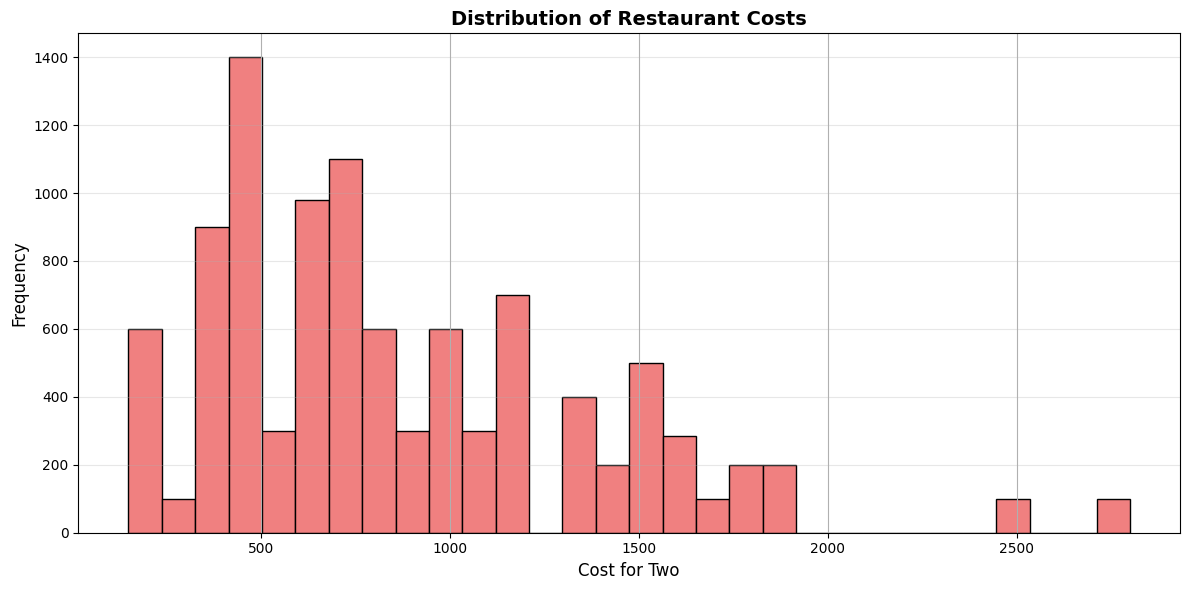

In [ ]:
# Chart - 2: Distribution of Restaurant Costs
plt.figure(figsize=(12, 6))
df['Cost'].hist(bins=30, edgecolor='black', color='lightcoral')
plt.title('Distribution of Restaurant Costs', fontsize=14, fontweight='bold')
plt.xlabel('Cost for Two', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

##### 1. Why did i pick the specific chart?

A histogram was chosen because Cost is a continuous numeric variable, and a histogram is the only chart that shows how continuous data is distributed in different bands revealing the shape, peaks, and gaps in one view which directly helpful to know better about where most restaurants are priced.

##### 2. What are the insights found from the chart?

- The distribution is right-skewed, meaning most restaurants are affordable and premium restaurants are rare.
- The peak is at ₹400–600, where the highest number of restaurants are concentrated.
- There is a natural gap around ₹1200 that visually splits the market into everyday dining at below than that and premium dining above to it.
- Very few restaurants exceed ₹2000, confirming that premium dining is a very niche segment in Hyderabad.

##### 3. Will the gained insights help creating a positive business impact?

- ₹400–600 is the most crowded segment, so restaurants here must compete on quality and loyalty, not price.
- Budget restaurants below ₹300 are underserved and can be promoted to price-sensitive users through discounts and combo deals.
- Premium restaurants above ₹1500 need a dedicated section so they reach the right audience instead of getting lost in search results.
- The ₹1200 gap means market,customers already splited in two categories. Zomato can personalise recommendations by occasion and spending intent.
#### Negative risk:
- Heavy concentration below ₹1000 keeps average order value as low pricing, which is limiting platform revenue growth unless premium restaurants are actively promoted.

#### Chart - 3 : Top 10 Cuisines (Univariate Analysis)

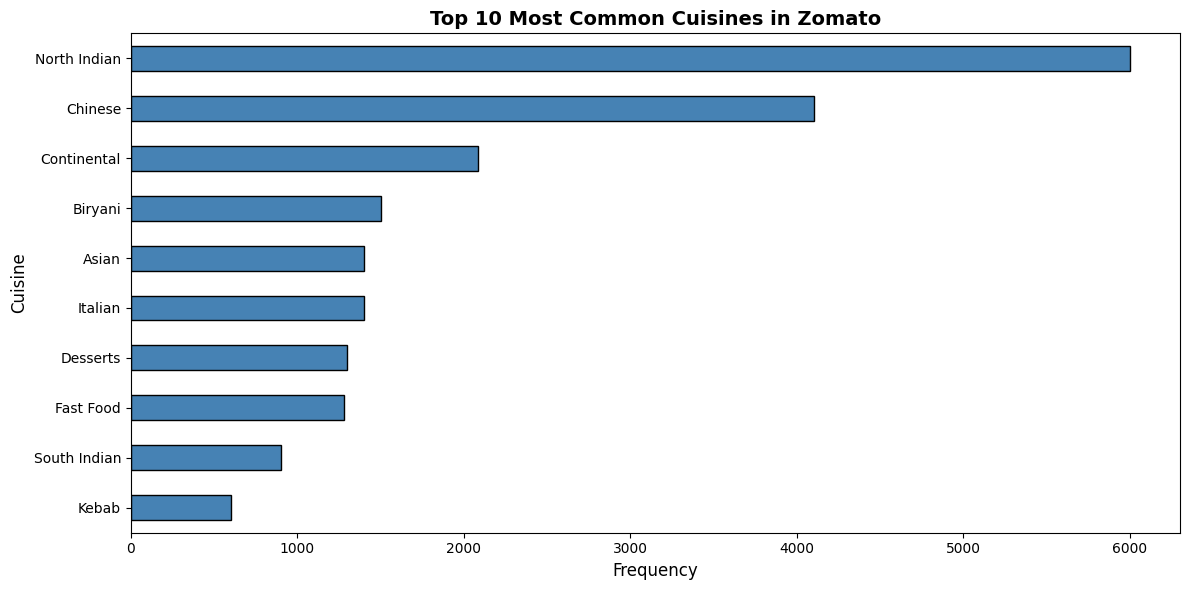

In [ ]:
# Chart - 3: Top 10 Cuisines (Categorical Univariate Analysis)
cuisines_exploded = df.assign(Cuisine=df['Cuisines'].str.split(', ')).explode('Cuisine')
top_cuisines = cuisines_exploded['Cuisine'].value_counts().head(10)
plt.figure(figsize=(12, 6))
top_cuisines.plot(kind='barh', color='steelblue', edgecolor='black')
plt.title('Top 10 Most Common Cuisines in Zomato', fontsize=14, fontweight='bold')
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Cuisine', fontsize=12)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

##### 1. Why did i pick the specific chart?

A **horizontal bar chart** was selected because Cuisines is a multi-label categorical variable. After splitting comma-separated values and counting individual cuisine frequencies, a bar chart ranks categories clearly and makes relative popularity immediately visible, so it's ideal for high-cardinality categorical data.

##### 2. What is/are the insight(s) found from the chart?


- **North Indian cuisines** dominates by a large margin, reflecting strong cultural demand.
- **Chinese** ranks second, Asian cuisines command significant market share.
- **Global cuisines** (Continental, Italian, American) coexist with regional specialties (Biryani, Kebab, Mughlai, Andhra) also preferable by customers.
- **Fast Food and Desserts** feature prominently, indicating strong casual/indulgence segments.

##### 3. Will the gained insights help creating a positive business impact?

**Positive Business Impact:**
- New entrants should consider **North Indian or Chinese** offerings to capture the largest audience.
- Niche cuisines (e.g., Andhra, South Indian) can build loyal, underserved customer bases.
- Platforms can optimise search filters and recommendations around top cuisine preferences.

**Negative Growth Risk:**
- Over-saturation in North Indian/Chinese restaurants intensifies competition. The differentiation on quality, pricing, or experience is essential to avoid being lost in the crowd.

##### Chart - 4: Review Length Distribution (Univariate Analysis)


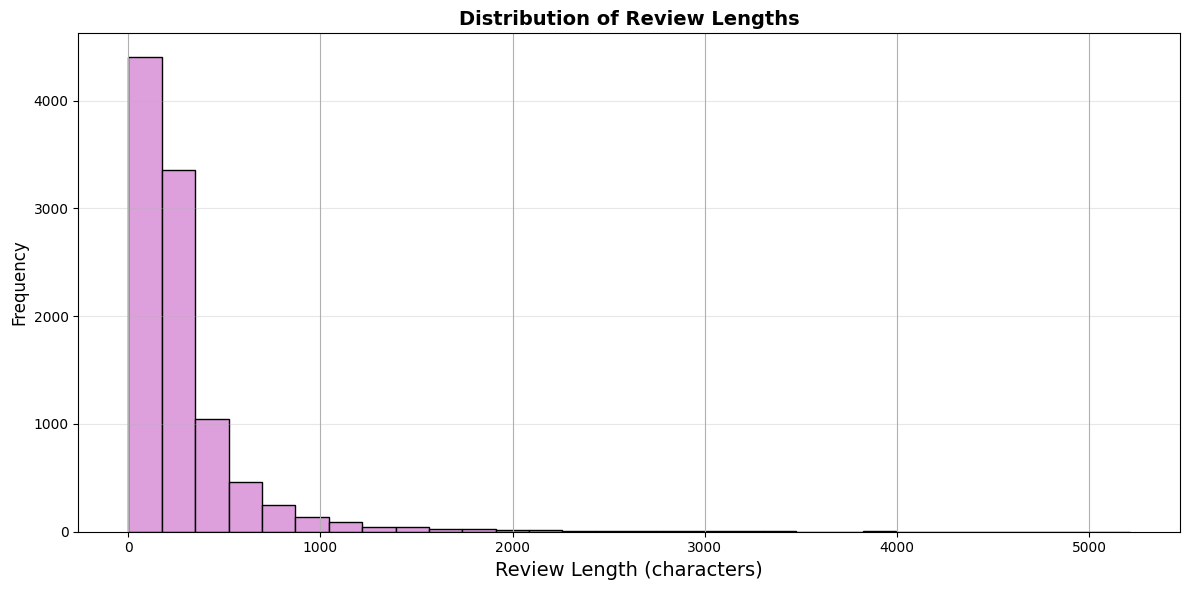

In [ ]:
# Chart - 4: Review Length Distribution (Univariate Analysis)
df['Review_Length'] = df['Review'].fillna('').apply(len)

plt.figure(figsize=(12, 6))
df['Review_Length'].hist(bins=30, edgecolor='black', color='plum')
plt.title("Distribution of Review Lengths", fontsize= 14, fontweight='bold')
plt.xlabel("Review Length (characters)", fontsize= 14)

plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


##### 1. Why did i pick the specific chart?

A **histogram with KDE** was selected because Review_Length is a continuous numerical variable derived from review text. It visualises the frequency distribution of review lengths, reveals skewness, and identifies whether most users write brief or detailed reviews — informing content strategy and NLP preprocessing decisions.

##### 2. What is/are the insight(s) found from the chart?


- **Most reviews are short** — the distribution peaks at low word counts, typical of online review platforms.
- The distribution is **right-skewed**, with a long tail of detailed reviews written by a minority of users.
- **Concise reviews dominate**, but detailed reviews (long tail) may carry stronger sentiment signals.
- Review length alone does not reliably predict rating direction.

##### 3. Will the gained insights help creating a positive business impact?

**Positive Business Impact:**
- Platforms should **make short review submission frictionless** while prompting more detail for extreme experiences.
- Detailed reviews provide richer qualitative data for NLP sentiment analysis and restaurant improvement insights.

**Negative Growth Risk:**
- If short, negative reviews accumulate without being acted upon (due to lack of detail), systemic quality issues go unaddressed — eroding ratings over time.

#### Chart - 5 : Distribution of Pictures (Univariate Analysis)

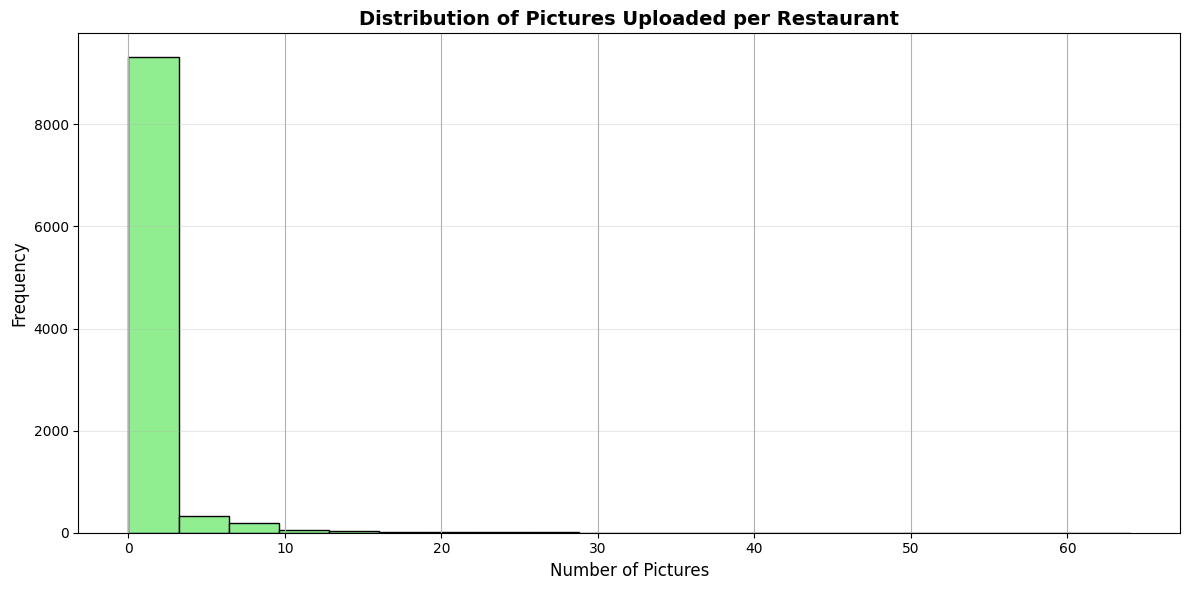

In [ ]:
# Chart - 5: Distribution of Pictures (Univariate Analysis)
plt.figure(figsize=(12, 6))
df['Pictures'].hist(bins=20, edgecolor='black', color='lightgreen')
plt.title('Distribution of Pictures Uploaded per Restaurant', fontsize=14, fontweight='bold')
plt.xlabel('Number of Pictures', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

##### 1. Why did i pick the specific chart?

A **histogram with KDE overlay** was chosen because Pictures is a discrete numerical variable. The histogram shows frequency at each count value, while KDE smooths the distribution curve — together they reveal skew, central tendency, and the presence of power users who upload many photos.

##### 2. What is/are the insight(s) found from the chart?


- **Overwhelming majority of reviews have 0 pictures** — visual contribution is rare.
- Frequency drops sharply after 0; very few reviews include even 1–2 images.
- A long right tail shows a small group of **power users** uploading 10–60+ pictures.
- Distribution is **heavily right-skewed**, confirming photo uploads are niche behaviour.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth?

**Positive Business Impact:**
- Platforms can run **an encouraging campaign for photo uploads** (badges, status tiers) to increase visual content volume.
- Identifying power-user photographers enables targeted influencer partnerships.
- Sparse but high-quality photos can be curated for marketing campaigns.

**Negative Growth Risk:**
- A photo-sparse platform appears less dynamic vs. visual-first competitors, potentially deterring discovery-focused users.

Chart - 6 : Top 10 Collections in the city (Univariate Analysis)

In [ ]:
collections_exploded = df.assign(Collection=df['Collections'].str.split(', ')).explode('Collection')
top_10_collections = collections_exploded['Collection'].value_counts().head(10)
top_10_names = top_10_collections.index
print(top_10_collections)

Collection
Great Buffets                                  2000
Food Hygiene Rated Restaurants in Hyderabad    1778
Trending This Week                             1400
Live Sports Screenings                         1300
Corporate Favorites                             900
Gold Curated                                    800
Top-Rated                                       800
Late Night Restaurants                          700
Hyderabad's Hottest                             700
Great Breakfasts                                700
Name: count, dtype: int64


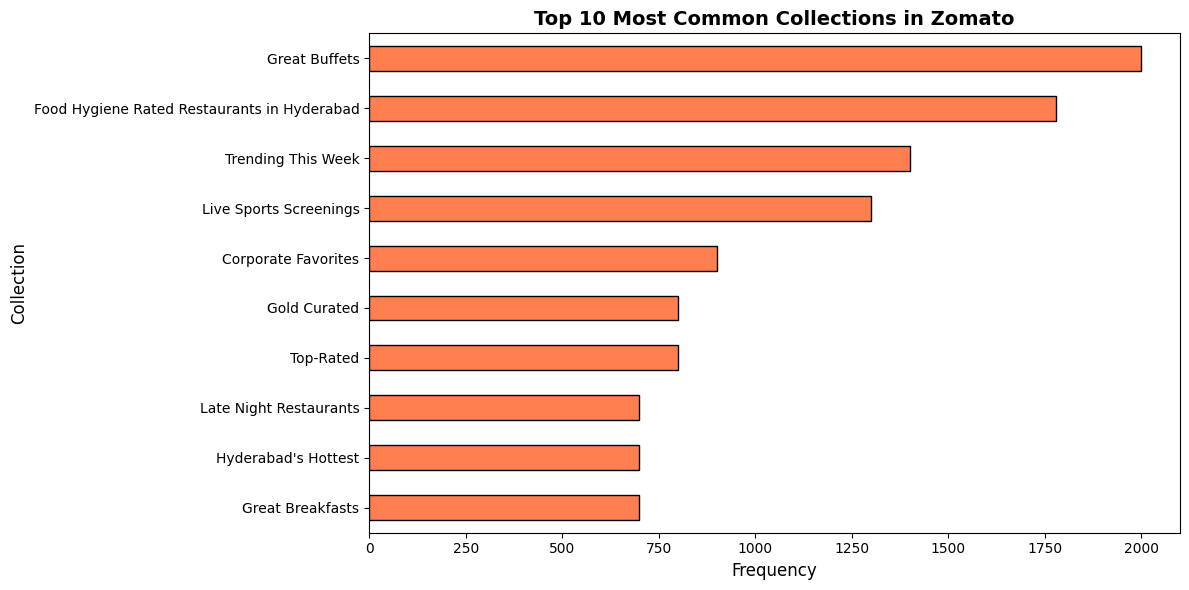

In [ ]:
# Chart - 6: Top 10 Collections (Categorical Univariate Analysis)
plt.figure(figsize=(12, 6))
top_10_collections.plot(kind='barh', color='coral', edgecolor='black')
plt.title('Top 10 Most Common Collections in Zomato', fontsize=14, fontweight='bold')
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Collection', fontsize=12)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

##### 1. Why did i pick the specific chart?

A **bar chart** was chosen to display collection frequencies because Collections is a multi-label categorical column. After splitting and counting individual tags, a bar chart clearly ranks the most popular dining categories — enabling quick identification of consumer preference patterns.

##### 2. What is/are the insight(s) found from the chart?


- **Great Buffets** tops the list — buffet-style dining has the widest appeal.
- **Hyderabad's Hottest** reflects strong local curation and trending dining interest.
- **Veggie Friendly** is highly prominent, highlighting significant vegetarian demand.
- **Food Hygiene Rated** ranks high — consumers actively value safety and cleanliness.
- Experience-driven collections (**Live Sports Screenings, Rooftops, Happy Hours**) confirm diners seek more than food alone.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth?

**Positive Business Impact:**
- Restaurants should seek listing in **high-frequency collections** (Buffets, Veggie Friendly, Hygienic) to increase discoverability.
- Investing in **experience features** (live sports, rooftop ambiance) helps qualify for experience-driven collections and premium positioning.

**Negative Growth Risk:**
- Restaurants failing hygiene ratings or veggie-friendliness standards miss large, actively filtering customer segments.

#### Chart - 7: Pictures vs Review Length (Bivariate Analysis)

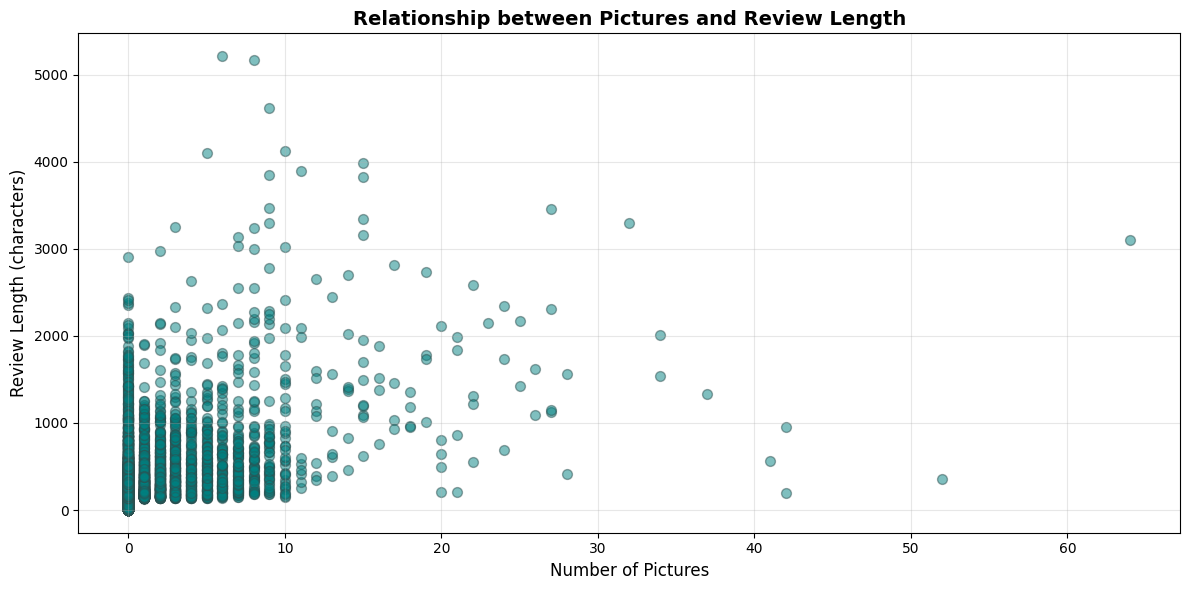

In [ ]:
# Chart - 7: Scatter - Pictures vs Review Length (Bivariate - Numerical Analysis)
plt.figure(figsize=(12, 6))
plt.scatter(df['Pictures'], df['Review_Length'], alpha=0.5, s=50, color='teal', edgecolors='darkslategray')
plt.title('Relationship between Pictures and Review Length', fontsize=14, fontweight='bold')
plt.xlabel('Number of Pictures', fontsize=12)
plt.ylabel('Review Length (characters)', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# To check the longest review present in dataset to get an idea about how its sentiment(positive, negative, neutral)
longest_string = df.sort_values(by='Review_Length', ascending=False)['Review'].iloc[0]
print(longest_string)

Hyderabadi Daawat as the name suggests has some authentic Hyderabadi food which you get to eat in the functions here in Hyderabad! Ever been to a Hyderabadi Daawat before? No not the hotel we're talking about a function, well if you've been to one then You definitely know how much a Hyderabadi loves food and how much he spends on the Menu! And here at Hyderabadi Daawat, the restaurant, you get the same splendid variety of dishes to enjoy! The hotel is very easy to locate! Its on the main road...while coming from ORR or Gachibowli side it comes on the right side and if you're coming from Miyapur side then it will be on Your left! The restaurant has simple yet beautiful interiors, very calm and cozy place! They also have Banquet hall and a Conference hall and they also undertake Catering orders for parties and functions! And after the "DASTAR" was set we sat down for the food and they first brought the YAKHNI SHORBA! Shorba is nothing but the soup! Yakhni Shorba is a dish from Kashmir...

##### 1. Why did i pick the specific chart?

A **scatter plot** was chosen to examine the relationship between two numerical variables: number of Pictures and Review_Length. Scatter plots reveal correlation strength, direction, clusters, and outliers — making it straightforward to assess whether visual and textual engagement co-occur in reviewer behaviour.

##### 2. What is/are the insight(s) found from the chart?


- **Strong positive trend**: Reviewers who upload more pictures also write longer reviews, confirming the heatmap correlation (r ≈ 0.47).
- **Majority of points cluster at (0 pictures, short review)** — most reviewers are brief and photo-free.
- A distinct **engaged-reviewer segment** (high pictures, long review) exists and appears consistently positive.
- Very few data points combine many pictures with very short reviews, suggesting effort signals commitment.
- **Highly dissatisfied reviewers rarely upload many photos** — visual content skews toward positive experiences.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth?

**Positive Business Impact:**
- Identifying **dual-engagement reviewers** (many photos + long reviews) enables targeted loyalty and influencer programs.
- Platform features that simplify simultaneous photo + text submission can increase overall content richness.

**Negative Growth Risk:**
- The rare case of a detailed negative review with multiple photos (e.g., unhygienic conditions) carries extreme credibility and virality risk — restaurants must proactively monitor and address such content.

### Chart - 8 : Rating Distribution by Number of Pictures (Bivariate Analysis)

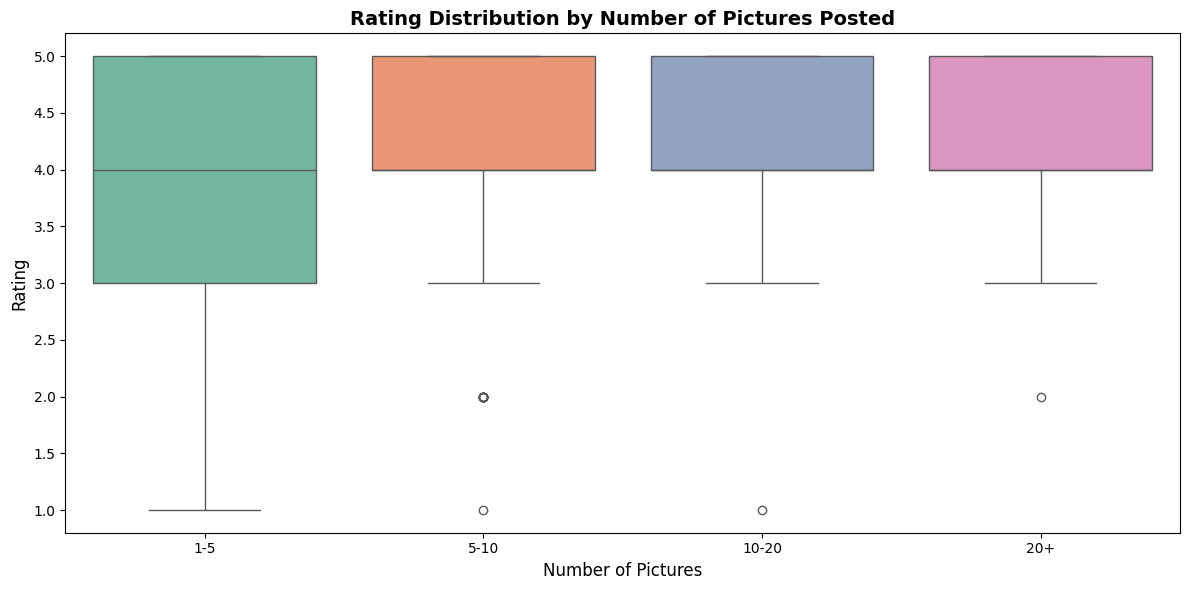

In [ ]:
# Chart - 8: Rating Distribution by Number of Pictures
df['Picture_Category'] = pd.cut(df['Pictures'], bins=[0, 5, 10, 20, 100], labels=['1-5', '5-10', '10-20', '20+'])
plt.figure(figsize=(12, 6))
sns.boxplot(x='Picture_Category', y='Rating', data=df, palette='Set2')
plt.title('Rating Distribution by Number of Pictures Posted', fontsize=14, fontweight='bold')
plt.xlabel('Number of Pictures', fontsize=12)
plt.ylabel('Rating', fontsize=12)
plt.tight_layout()
plt.show()

##### 1. Why did i pick the specific chart?

A boxplot is used to compare ratings across different groups. It shows the middle value, how spread out the ratings are, and any unusual points, making differences easy to see.

##### 2. What are the insights found from the chart?

- All groups have almost the same average rating, around 4.  
- Ratings in every group are spread widely between 3 and 5.  
- Even restaurants with many photos can still get very low ratings sometimes.

##### 3. Will the gained insights help creating a positive business impact?


Yes. Insights are -
- More photos do not mean better ratings.  
- Photos can help show which restaurants look better.  
- Ratings are very mixed, so customer experience is not consistent.  

#### Risk:
- One bad photo can damage a restaurant’s image quickly.

### **Exploratory Bivariate Analysis**
This subsection details the pairwise numerical comparisons and multi-variable distributions designed to expose underlying trends in user interactions, photo uploads, and textual reviews.


#### Chart - 9 :  Cost vs Rating Scatter Plot (Bivariate Analysis)

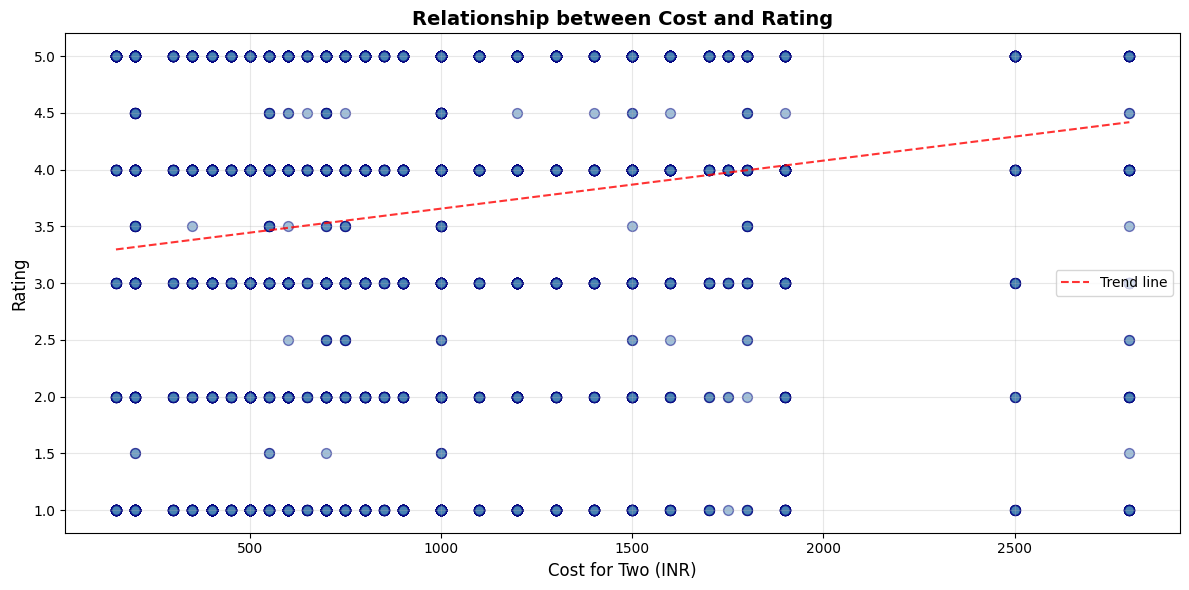

In [ ]:
# Chart - 9: Cost vs Rating Scatter Plot (Bivariate - Numerical Analysis)
plt.figure(figsize=(12, 6))
plt.scatter(df['Cost'], df['Rating'], alpha=0.5, s=50, color='steelblue', edgecolors='navy')

# Filter out NaN values from both 'Cost' and 'Rating' simultaneously for polyfit
valid_data = df[['Cost', 'Rating']].dropna()

# Calculate polynomial fit only on valid data
z = np.polyfit(valid_data['Cost'], valid_data['Rating'], 1)
p = np.poly1d(z)

# Plotting the trend line over the range of the valid 'Cost' data
plt.plot(valid_data['Cost'].sort_values(), p(valid_data['Cost'].sort_values()), "r--", alpha=0.8, label='Trend line')
plt.title('Relationship between Cost and Rating', fontsize=14, fontweight='bold')
plt.xlabel('Cost for Two (INR)', fontsize=12)
plt.ylabel('Rating', fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##### 1. Why did i pick the specific chart?

Because we are comparing two numbers i:e. cost vs rating.
A scatter plot shows how they move together, and the trend line tells us if higher cost means better ratings or due to just better marketing.

##### 2. What is/are the insight(s) found from the chart?

- There is no strong link between price and rating, good ratings appear at all price levels.  
- Most restaurants are priced between ₹400–800, so most ratings come from this range.  
- Expensive restaurants can still get low ratings, high price does not mean good experience.  
- Budget restaurants (₹200–400) often get high ratings, showing good value for money.  
- A few high-cost restaurants (₹1500+) get great ratings, showing some premium places are doing well.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth?

**Positive Business Impact:**
- Restaurants should focus on food quality, service, and ambiance instead of relying on price to signal quality.  
- Budget restaurants can do good by promoting value for money, combining affordability with good experience.  

**Negative Growth Risk:**
- High-cost restaurants that fail to meet expectations risk strong customer backlash, as people expect more when they pay more.

#### Chart - 10 : Restaurant Collections vs Rating Box Plot (Bivariate Analysis)

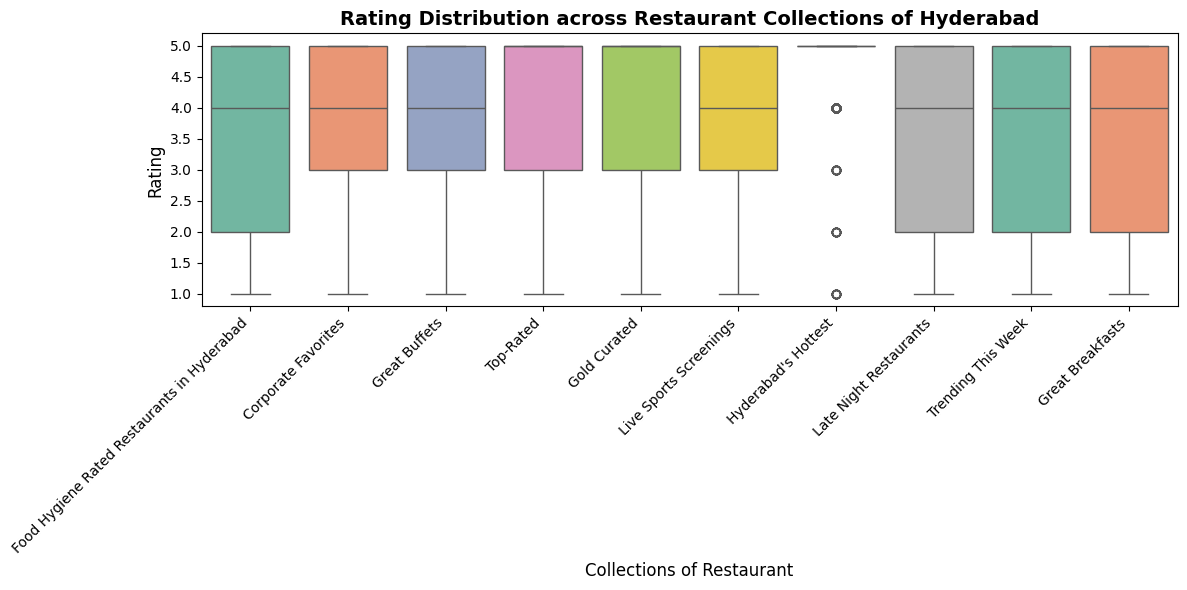

In [ ]:
df_top_10 = collections_exploded[collections_exploded['Collection'].isin(top_10_names)]

plt.figure(figsize=(12, 6))
sns.boxplot(x='Collection', y='Rating', data=df_top_10, palette='Set2')
plt.title('Rating Distribution across Restaurant Collections of Hyderabad', fontsize=14, fontweight='bold')
plt.xlabel('Collections of Restaurant', fontsize=12)
plt.ylabel('Rating', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### 1. Why did i pick the specific chart?

A box plot directly compares the populations, spread, and outliers of ratings across multiple categorical collections, making it easy to spot on which groups consistently perform well and which are not.

##### 2. What is/are the insight(s) found from the chart?

- Hyderabad's Hottest" dominates with a median rating of 5.0, and only few outliers on lower side.
- Median ratings are around 3.5 to 4.0 in all collections, showing generally good experiences.  
- 'Top-Rated' and 'Gold Curated' have slightly higher ratings, which supports their quality label.
- Food Hygiene Rated", "Late Night Restaurants", "Trending This Week", and "Great Breakfasts" show severe inconsistency by their 25th percentiles fall into 2.0 ratings, meaning a quarter of restaurants in these collections have poor ratings.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:**
- By directing customers to "Hyderabad's Hottest", "Top-Rated", and "Gold Curated" collections almost guarantees a 4.0 to 5.0 user experience, causing platform retention and more trusts.

**Negative Growth Risk:**
- The "Food Hygiene Rated" collection contains a significant bottom level 2.0 rated restaurants that flag hygiene issues which severely damages platform credibility and user safety, trusts. These collections require stricter actions.

#### Chart - 11 : Restaurant Collections vs Cost Box Plot (Bivariate Analysis)

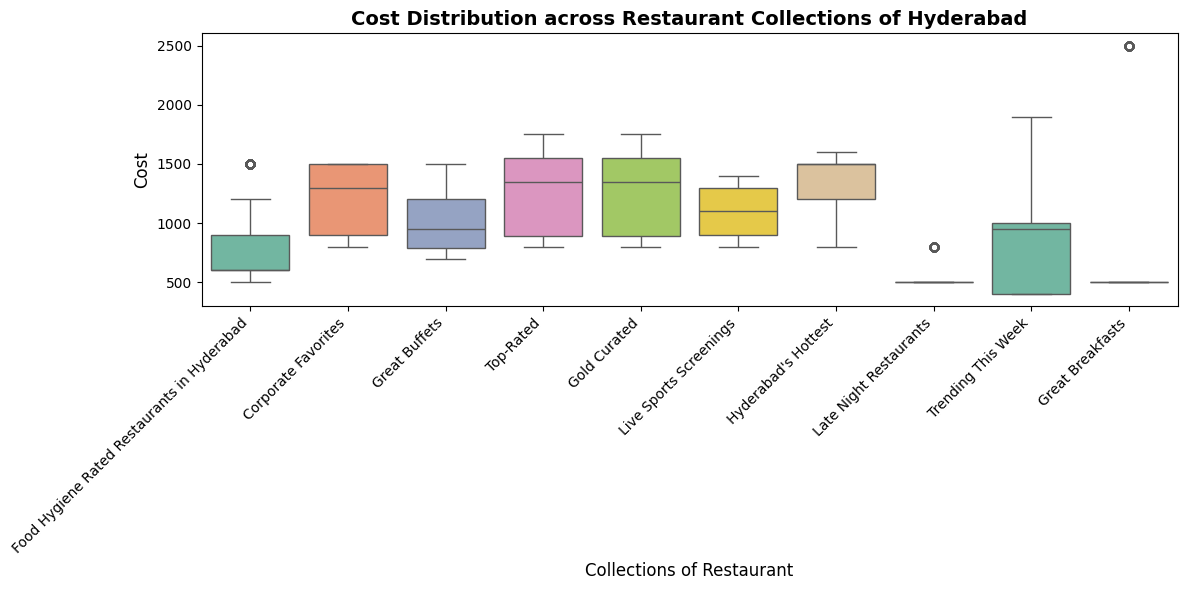

In [ ]:
df_top_10 = collections_exploded[collections_exploded['Collection'].isin(top_10_names)]

plt.figure(figsize=(12, 6))
sns.boxplot(x='Collection', y='Cost', data=df_top_10, palette='Set2')
plt.title('Cost Distribution across Restaurant Collections of Hyderabad', fontsize=14, fontweight='bold')
plt.xlabel('Collections of Restaurant', fontsize=12)
plt.ylabel('Cost', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### 1. Why did i pick the specific chart?

A **box plot** was chosen to visualise Cost distribution across top Collections. It captures median pricing, spread, and outliers per category helps in comparison of typical price points across different restaurant groups and reveals how collection spots with pricing strategy.

##### 2. What is/are the insight(s) found from the chart?


- "Hyderabad's Hottest", "Top-Rated", and "Gold Curated" have the highest median costs i:e ₹1350 to ₹1500.
- "Late Night Restaurants" and "Great Breakfasts" are strictly budget-friendly, cost is around minimum of ₹500.
- "Trending This Week" is highly inconsistent, by spreading from below ₹500 up to extreme ₹2500 as outlier.
- "Food Hygiene Rated" restaurants are mostly affordable, as all items sitting below ₹900 not beyond spreaded.

##### 3. Will the gained insights help creating a positive business impact?

**Positive Business Impact:**
- Directing price sensitive users to "Late Night Restaurants" or "Great Breakfasts" guarantees as budget friendly options, this will increase order volume, and showing the high spending customers to "Gold Curated" guarantees matching premium expectations will result more profit for each order eventually to Zomato.

**Negative Growth Risk:**
- The extreme price variance in "Trending This Week" causes mixing of cheap and highly expensive restaurants under one tag without clear price indicators frustrates users and hurts conversion rates.

#### Chart - 12: Rating Distribution by Top Cuisines (Bivariate Analysis)

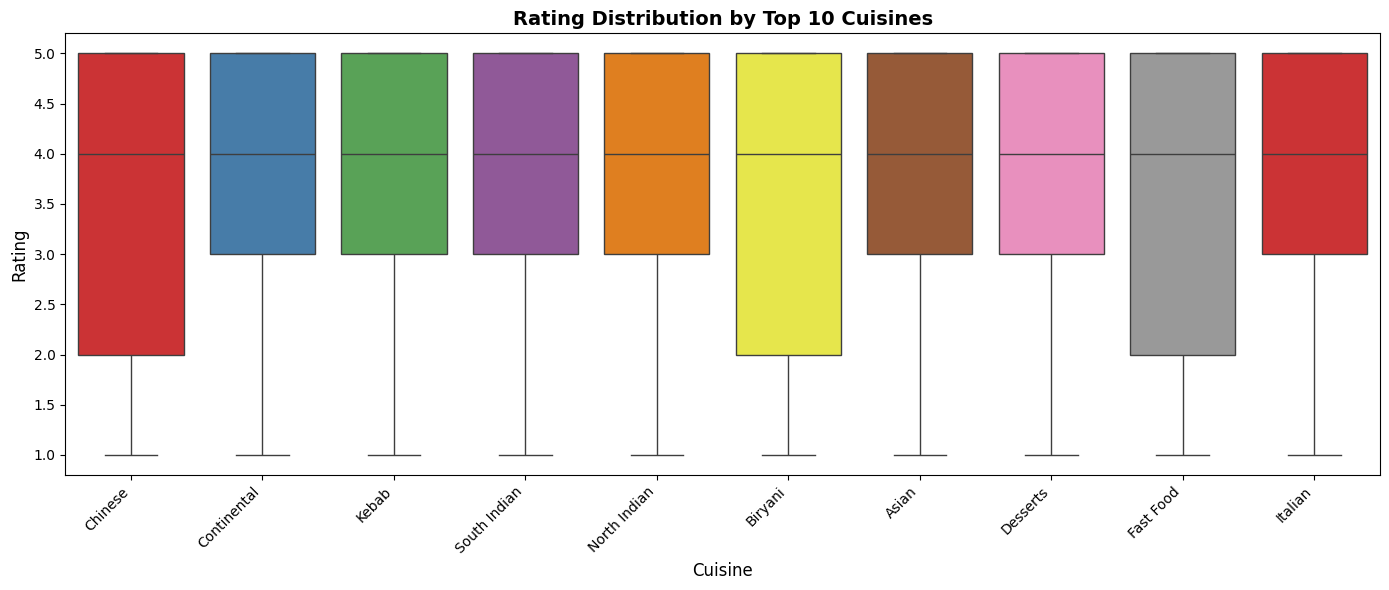

In [ ]:
#cuisines_exploded = df.assign(Cuisine=df['Cuisines'].str.split(', ')).explode('Cuisine')
top_10_cuisines = cuisines_exploded['Cuisine'].value_counts().head(10).index
df_top_cuisines = cuisines_exploded[cuisines_exploded['Cuisine'].isin(top_10_cuisines)].reset_index(drop=True)

plt.figure(figsize=(14, 6))
sns.boxplot(x='Cuisine', y='Rating', data=df_top_cuisines, palette='Set1')
plt.title('Rating Distribution by Top 10 Cuisines', fontsize=14, fontweight='bold')
plt.xlabel('Cuisine', fontsize=12)
plt.ylabel('Rating', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### 1. Why did i pick the specific chart?

This box plot directly compares median satisfaction through ratings across the most popular cuisines, exploring which food categories deliver consistent quality versus unpredictable experiences.

##### 2. What is/are the insight(s) found from the chart?

- All top 10 cuisines share overall same median rating of 4.0.
- "Chinese", "Biryani", and "Fast Food" show severe inconsistency by the spread lower to 2.0 rating, meaning more restatuarant of highly popular categories deliver poor experiences.
- "Continental", "Kebab", "South Indian", "North Indian", "Asian", "Desserts", and "Italian" all are their ratings sustainably between 3.0 and 5.0.

##### 3. Will the gained insights help creating a positive business impact?

**Positive Business Impact:**
- Promoting highly consistent cuisines like North Indian or Italian to the new or frequent users minimizes the risk of a bad meal experiences, securing user trust and boosting repeat order rates.

**Negative Growth Risk:**
- The extreme ratings volatility in "Chinese", "Biryani" and "Fast Food" highlights substandard vendors, without strict filters guarantees a high volume of bad customer experiences, results platform churning higher.

#### Chart - 13: Cost Distribution by Top Cuisines (Bivariate Analysis)

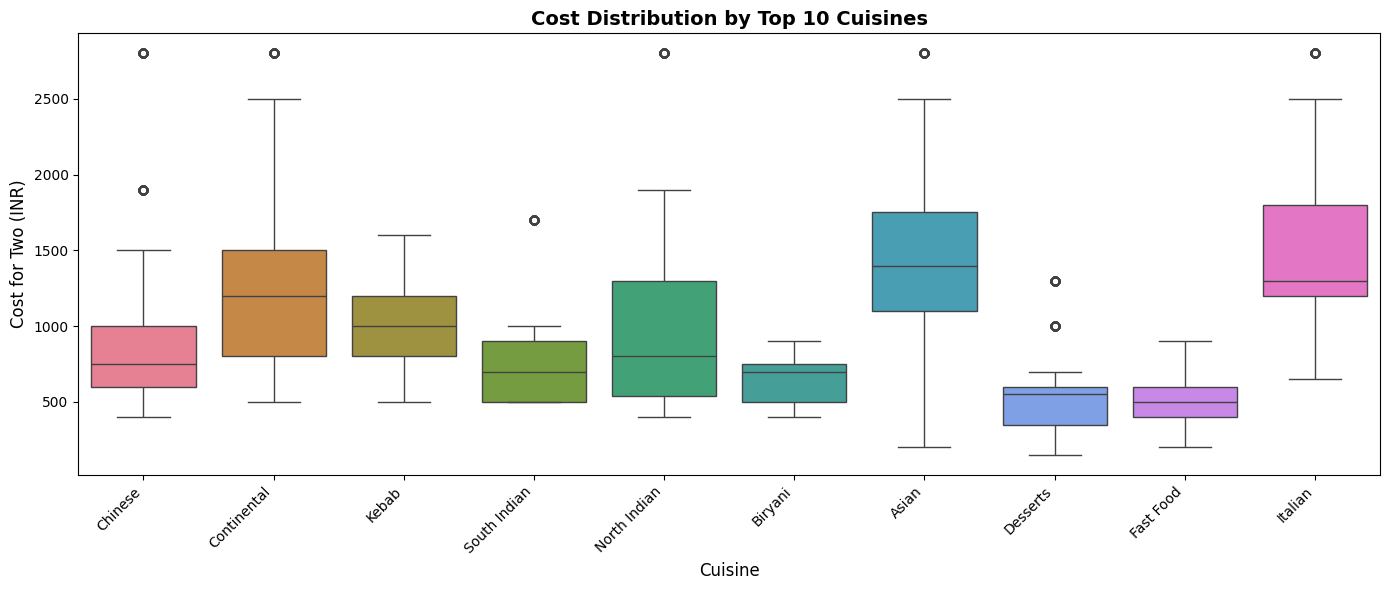

In [ ]:
cuisines_exploded = df.assign(Cuisine=df['Cuisines'].str.split(', ')).explode('Cuisine')
top_10_cuisines = cuisines_exploded['Cuisine'].value_counts().head(10).index
df_top_cuisines_cost = cuisines_exploded[cuisines_exploded['Cuisine'].isin(top_10_cuisines)]

plt.figure(figsize=(14, 6))
sns.boxplot(x='Cuisine', y='Cost', data=df_top_cuisines_cost, palette='husl')
plt.title('Cost Distribution by Top 10 Cuisines', fontsize=14, fontweight='bold')
plt.xlabel('Cuisine', fontsize=12)
plt.ylabel('Cost for Two (INR)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### 1. Why did i pick the specific chart?

This box plot directly compares median pricing and cost spread across the most popular cuisines, exposing which food categories are in budget segments or premium dining experiences.

##### 2. What is/are the insight(s) found from the chart?

- "Desserts" and "Fast Food" have the lowest median costs around ₹500 and with limited spreads making those consistent, budget friendly segments.
- "Biryani" and "South Indian" are also 2nd affordable segments with their costs sitting below ₹1000.
- "Asian", "Italian", and "Continental" carry the highest medians between ₹1000 to ₹1500 as premium choices.
- "North Indian" and "Chinese" cover cost ranges from budget to premium, reflecting highly diverse restaurants comes under it with extreme upper outliers above ₹2500.

##### 3. Will the gained insights help creating a positive business impact?

**Positive Business Impact:**
- Pricing strategies must be aligned with category expectations, like restaurants of "Fast Food" and "Desserts" should focus on order volume and convenience, while "Asian" and "Italian" restaurants can acquire higher margins by focusing on premium experiences.

**Negative Growth Risk:**
- In some categories, if charging premium prices such as ₹1500 and above without exceptional justification, this directly drives negative reviews and increases customer churn.

#### Chart - 14: Cuisine and Rating Tier vs Average Review Length (Bivariate Analysis)

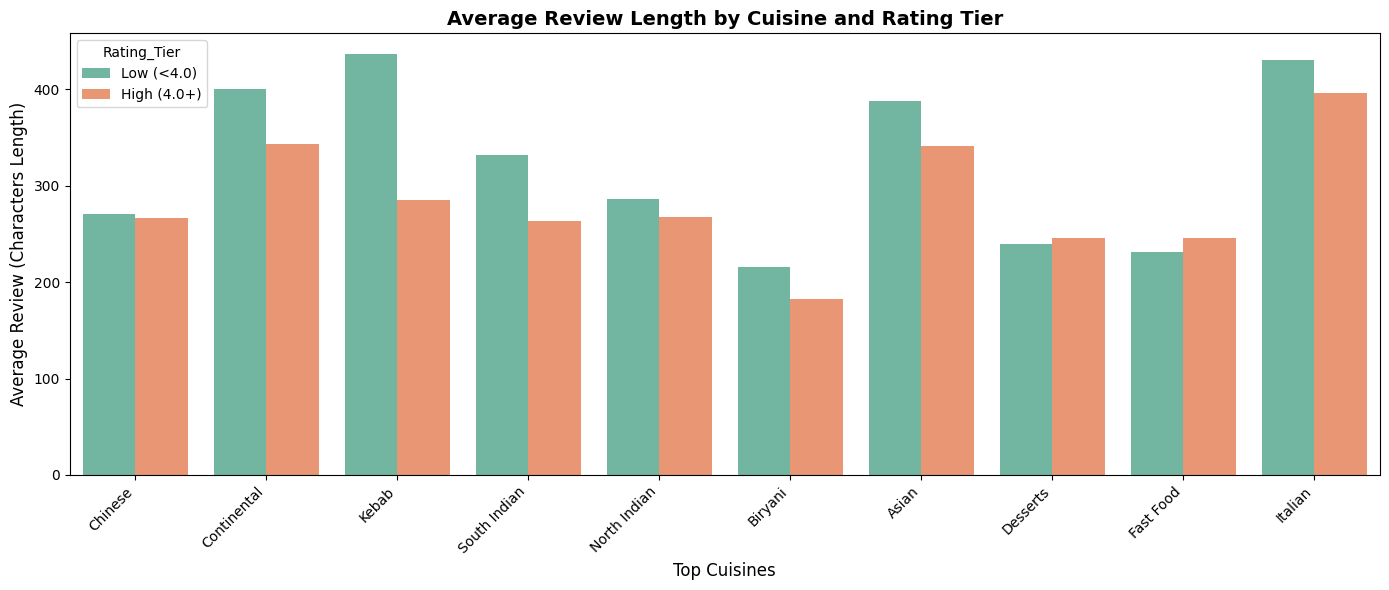

In [ ]:
# Rating Tier(low(<3.9),high(>3.9))
df['Rating_Tier'] = pd.cut(df['Rating'], bins=[0, 3.9, 5.0], labels=['Low (<4.0)', 'High (4.0+)'])
cuisines_exploded = df.assign(Cuisine=df['Cuisines'].str.split(', ')).explode('Cuisine')
top_10_cuisines = cuisines_exploded['Cuisine'].value_counts().head(10).index
df_top_10 = cuisines_exploded[cuisines_exploded['Cuisine'].isin(top_10_cuisines)]

# Plot bar chart
plt.figure(figsize=(14,6))
sns.barplot(
    x='Cuisine',
    y='Review_Length',
    hue='Rating_Tier',
    data=df_top_10,
    palette='Set2',
    errorbar=None)
plt.title('Average Review Length by Cuisine and Rating Tier', fontsize=14, fontweight='bold')
plt.xlabel('Top Cuisines', fontsize=12)
plt.ylabel('Average Review (Characters Length)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### 1. Why did i pick the specific chart?

A grouped bar chart directly compares customer  review length against satisfaction with rating tier across top cuisines, revealing users invest more time describing a good experience or operational failure.

##### 2. What is/are the insight(s) found from the chart?

- Customers write the longest reviews of more than 400 characters when they dissatisfied with premium cuisines like Kebab, Italian, Continental.

- In case of "Desserts" and "Fast Food" the positive reviews are slightly longer than negative ones, showing brand advocacy.

- "Biryani" generates the lowest engagement around 220 characters, proving it is a high volume, but less loyal cuisines.

##### 3. Will the gained insights help creating a positive business impact?

**Positive Business Impact:**
- The review length specifically 400+ character complaints should be isolated to find and fix service bottlenecks such as cold food, rude staff behaviours etc. without reading thousands of 5 star rating & "good food" reviews.

**Negative Growth Risk:**
- Ignoring long detailed negative reviews in premium categories destroys conversion rates, also high paying customers read these reviews before booking. By leaving these reviews unaddressed  will cause critical revenue loss.

#### Chart - 15: Cost vs Rating and Top Cuisines (Bivariate Analysis)

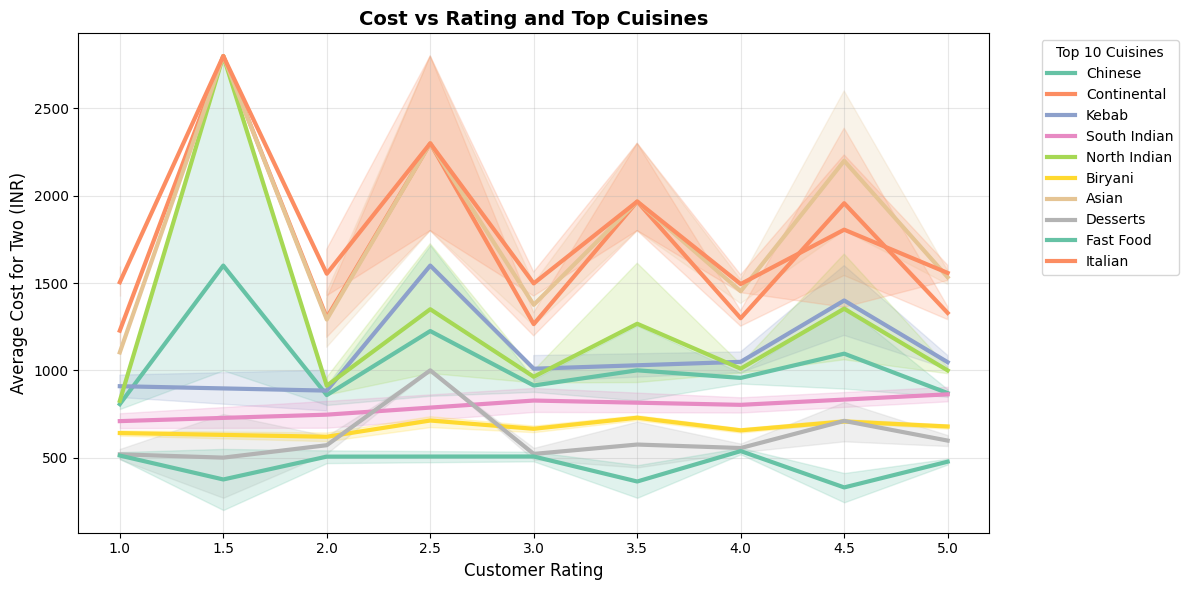

In [ ]:
cuisines_exploded = df.assign(Cuisine=df['Cuisines'].str.split(', ')).explode('Cuisine')
top_10_cuisines = cuisines_exploded['Cuisine'].value_counts().head(10).index
df_top_10 = cuisines_exploded[cuisines_exploded['Cuisine'].isin(top_10_cuisines)]

# Plot line plot
plt.figure(figsize=(12, 6))
sns.lineplot(
    x='Rating',
    y='Cost',
    hue='Cuisine',
    data=df_top_10,
    linewidth=3,
    palette='Set2'
    )
plt.title('Cost vs Rating and Top Cuisines', fontsize=14, fontweight='bold')
plt.xlabel('Customer Rating', fontsize=12)
plt.ylabel('Average Cost for Two (INR)', fontsize=12)
plt.legend(title='Top 10 Cuisines', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##### 1. Why did i pick the specific chart?

A line plot directly tracks the relationship between customer satisfaction and spend across cuisines. It exposes which food categories possess pricing volatility, and how pricing behaves at perfect ratings.

##### 2. What is/are the insight(s) found from the chart?

- "Fast Food", "Desserts", "South Indian", and "Biryani" have completely flat price under ₹1000. Ratings do not impact their cost, they are commoditized.
- "Italian" and "Asian" show extreme price volatility with spikes above ₹2500 at remarkably low ratings between 1.5 and 2.5. This indicates highly unpredictable pricing.
- At 5.0 rating, the costs for premium cuisines stabilize, proving the highest rated restaurants do not rely on extreme, outlier pricing.

##### 3. Will the gained insights help creating a positive business impact?

**Positive Business Impact:**
- Restaurants of commoditized categories like 'Fast Food', 'Biryani' must compete on order volume, speed, efficiency. The data proves prices can not be raised to boost margins, even when achieving 5.0 rating.

**Negative Growth Risk:**
- 'Italian' and 'Asian' restaurants having poorly ratings like 1.5 to 2.5 highlight a severe value mismatch. Allowing these highly overpriced, underperforming restaurants to remain visible on the platform destroys customer trust and customers churn.

#### Chart - 16 - Correlation Heatmap (Interdependability of Features)

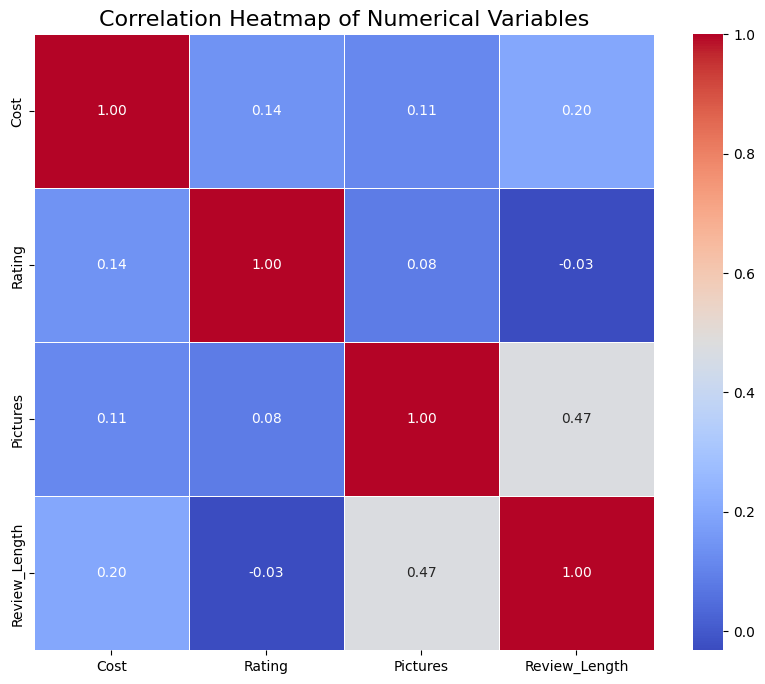

In [ ]:
# Selecting numerical columns for correlation analysis
numerical_df = df[['Cost', 'Rating', 'Pictures', 'Review_Length']].copy()

# Calculate the correlation matrix
correlation_matrix = numerical_df.corr()

# Create the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of Numerical Variables', fontsize=16)
plt.show()

##### 1. Why did i pick the specific chart?

A correlation heatmap reveals the exact mathematical relationships between spend, satisfaction, and customer effort, identifying which metrics actually move together and which are false assumptions.

##### 2. What is/are the insight(s) found from the chart?

- Pictures and Review_Length share the strongest mathematical correlation with coefficient 0.49. Customers who give more effort to upload photos are highly likely to also write detailed reviews.
- 0.14 is the correlation coefficient between Cost and Rating which is extremely weak. High priced restaurants do not automatically generate higher customer satisfaction scores.
- Rating has nearly zero correlation(-0.04) with Review_Length and customers write long reviws for both bad and good experiences, proving length only cannot predict if a review is positive or negative.

3. Will the gained insights help creating a positive business impact?

**Positive Business Impact:**
- Pictures, Review_Length can be used to optimize the user interface. Maximum user generated content must be audited for improvement of customers meals experiences.

**Negative Growth Risk:**
- As per 0.14 correlation coefficient, if platform's recommendation algorithm automatically pushes expensive restaurants to highpaying users expecting premium experiences, it will lead to mismatched expectations, bad reviews, and churning.

#### Chart - 17 - Pair Plot for Numerical Metrics Comparisions

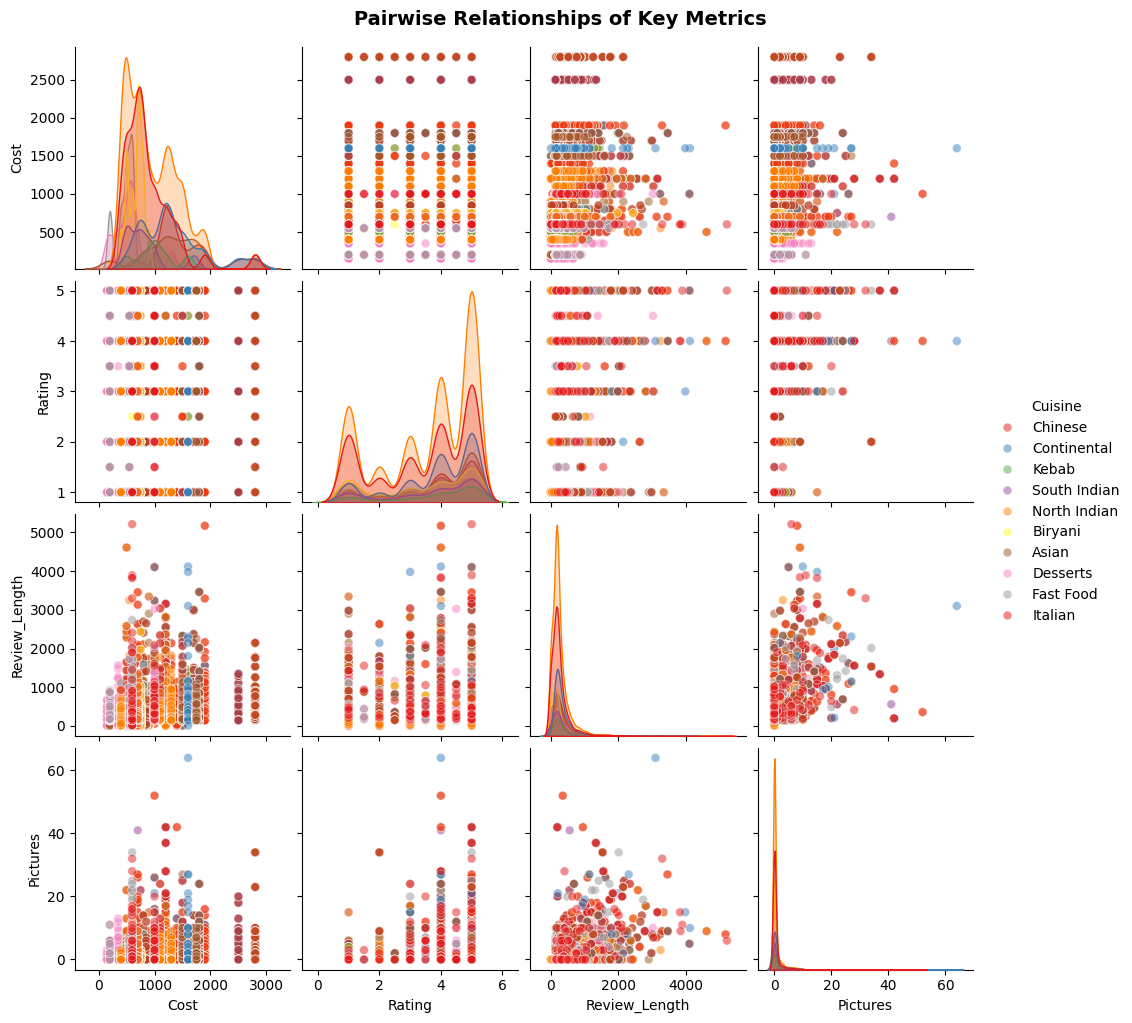

In [ ]:
# Creating rating tiers for metric classification
if 'Rating_Tier' not in df.columns:
    df['Rating_Tier'] = pd.cut(df['Rating'], bins=[0, 3.9, 5.0], labels=['Low (<4.0)', 'High (4.0+)'])

cuisines_exploded = df.assign(Cuisine=df['Cuisines'].str.split(', ')).explode('Cuisine')
top_10_cuisines = cuisines_exploded['Cuisine'].value_counts().head(10).index
df_top_10 = cuisines_exploded[cuisines_exploded['Cuisine'].isin(top_10_cuisines)]

# Numerical and categorical columns for plotting
cols_to_plot = ['Cost', 'Rating', 'Review_Length', 'Pictures', 'Cuisine']
df_pair = df_top_10[cols_to_plot].dropna()
# Visualize the pair-plot
sns.pairplot(
    df_pair,
    hue='Cuisine',
    palette='Set1',
    diag_kind='kde',
    plot_kws={'alpha': 0.5, 's': 40, 'edgecolor': 'w'})
plt.suptitle('Pairwise Relationships of Key Metrics', y=1.02, fontsize=14, fontweight='bold')
plt.show()

##### 1. Why did i pick the specific chart?

The filtered pair plot shows mathematical relationships and probability distributions across numerical variables, using top 10 cuisines to identify if different food types influence user behavior and spending patterns.

##### 2. What is/are the insight(s) found from the chart?

- Pictures and Review_Length share upward pattern. Customers who give more effort to upload photos are highly likely to also write detailed reviews, and this remains consistent across all 10 top cuisines.
- The diagonal density plots reveal that Rating is heavily bipolarized. Customers primarily write reviews for extreme experiences such as good or bad, causing peak at the 4.0–5.0 mark and a secondary bump at 1.0–2.0,
- The scatter plots for Cost versus Rating display heavy fluctuations such as high priced restaurants do not automatically generate higher customer satisfaction scores in any specific food category.

3. Will the gained insights help creating a positive business impact?

**Positive Business Impact:**
- By optimizing Pictures and Review_Length in algorithm, and considering this user contents to directly improve meal experiences.

**Negative Growth Risk:**
- Due to heavy Cost vs Rating overlap, algorithms blindly promoting expensive restaurants for premium experence that will cause mismatched expectations, bad reviews, and customers churning.

## ***5. Hypothesis Testing***

**We ran 3 statistical tests to prove our assumptions, that are :**

1. **Statement 1 (from Chart 10 – Rating vs. Collections):** Restaurants in the 'Top-Rated' collection have a significantly higher average rating than non-'Top-Rated' restaurants.

2. **Statement 2 (from Chart 13 – Cost vs. Cuisines):** 'Continental' cuisine restaurants have a significantly higher average Cost-for-Two than 'Fast Food' cuisine restaurants.

3. **Statement 3 (from Chart 16 – Correlation Heatmap):** There is a significant positive correlation between the number of pictures uploaded and review length, meaning users who upload photos always write longer reviews."

### Hypothetical Statement - 1

**Statement 1:** Rating difference between Top-Rated vs. non-Top-Rated restaurants.

- **H₀ (Null):** There is no significant difference in average ratings between Top-Rated and non-Top-Rated restaurants. (μ_top = μ_other)
- **H₁ (Alternate):** Top-Rated restaurants have a significantly higher average rating than non-Top-Rated restaurants. (μ_top ≠ μ_other)

In [ ]:
# Filter groups (handling NaN also)
top_rated = df[df['Collections'].fillna('').str.contains('Top-Rated')]['Rating'].dropna()
other_rated = df[~df['Collections'].fillna('').str.contains('Top-Rated')]['Rating'].dropna()

# Perform Welch's T-Test (equal_var=False because group sizes differ)
t_stat, p_val = ttest_ind(top_rated, other_rated, equal_var=False)

print(f"""T-Statistic: {t_stat:.4f}
P-Value: {p_val:.6f}""")

if p_val < 0.05:
    print("Result: Reject H0 - Top-Rated restaurants have significantly different average ratings.")
else:
    print("Result: Fail to Reject H0 - No significant difference in average ratings between Top-Rated and non-Top-Rated restaurants.")

T-Statistic: 8.2480
P-Value: 0.000000
Result: Reject H0 - Top-Rated restaurants have significantly different average ratings.


##### Which statistical test have you done to obtain P-Value?

**Welch's Independent T-Test** was used comparing the means of two uneven, independent groups: Top-Rated vs. non-Top-Rated restaurants. P-value was computed at α = 0.05.

##### Why did you choose the specific statistical test?

**Welch's T-Test** was chosen because:
- The hypothesis compares means of a continous numerical variable (Rating) across two independent groups.
- Groups are mutually exclusive i:e - a restaurant is either Top-Rated or not.
- Welch's variant (equal_var=False) is used because as group sizes differ and equal variance cannot be assumed, here it is more robust and reduces Type I error risk.

### Hypothetical Statement - 2

**Statement 2:** Is Continental food mathematically proven to be more expensive than Fast Food?

- **H₀ (Null):** Average Cost-for-Two for Continental restaurants is not higher than for Fast Food restaurants. (μ_continental ≤ μ_fast_food)
- **H₁ (Alternate):** Average Cost-for-Two for Continental restaurants is significantly higher than for Fast Food restaurants. (μ_continental > μ_fast_food)

In [ ]:
# Isolated costs for the two cuisines
continent_cost = df[df['Cuisines'].fillna('').str.contains('Continental')]['Cost'].dropna()
fast_cost = df[df['Cuisines'].fillna('').str.contains('Fast Food')]['Cost'].dropna()
# Perform Welch's T-Test
t_stat, p_val = ttest_ind(continent_cost, fast_cost, equal_var=False)
# One-tailed p-value
p_val_one_tailed = p_val/ 2
print(f"""T-Statistic: {t_stat:.4f}
P-Value (one tailed): {p_val_one_tailed:.6f}""")
if p_val_one_tailed < 0.05 and t_stat > 0:
    print("Result: Reject H0 - Continental cuisine is significantly more expensive than Fast Food.")
else:
    print("Result: Fail to Reject H0 - No significant difference in cost between Continental and Fast Food.")

T-Statistic: 59.7854
P-Value (one tailed): 0.000000
Result: Reject H0 - Continental cuisine is significantly more expensive than Fast Food.


##### Which statistical test have you done to obtain P-Value?

**Welch's Independent T-Test (one-tailed)** was used comparing the mean Cost of two independent groups: Continental vs. Fast Food. The p-value was halved since H₁ is directional.

##### Why did you choose the specific statistical test?

**Welch's T-Test** was chosen because:
- ​The hypothesis compares means of a numerical variable (Cost) across two independent groups.
- H₁ is directional (Continental > Fast Food), making a one-tailed test appropriate to maximise statistical power in the specified direction.
- Welch's variant (equal_var=False) strictly handles the unequal group sizes and variances naturally found between distinct cuisine categories.

### Hypothetical Statement - 3

**Statement 3:** Correlation between Pictures uploaded and Review Length.

- **H₀ (Null):** There is no significant positive correlation between Pictures and Review_Length. (ρ ≤ 0)
- **H₁ (Alternate):** There is a significant positive correlation between Pictures and Review_Length. (ρ > 0)

In [ ]:
# Drop missing values to align data
valid_data = df[['Pictures', 'Review_Length']].dropna()

# Pearson Correlation (returns two-tailed by default)
corr, p_val_two_tailed = pearsonr(valid_data['Pictures'], valid_data['Review_Length'])

# Halve the p-value, for a one-tailed test (since H1 is ρ > 0)
p_val = p_val_two_tailed / 2

print(f"Pearson Correlation: {corr:.4f}")
print(f"P-Value (one-tailed): {p_val:.6f}")

if p_val < 0.05 and corr > 0:
    print("Result: Reject H0 - There is a significant positive correlation between Pictures and Review Length.")
else:
    print("Result: Fail to Reject H0 - There's no significant positive correlation.")

Pearson Correlation: 0.4727
P-Value (one-tailed): 0.000000
Result: Reject H0 - There is a significant positive correlation between Pictures and Review Length.


##### Which statistical test have you done to obtain P-Value?

**Pearson's Correlation Coefficient Test** was used. It measures the linear relationship between two numerical variables (Pictures, Review_Length). A one-tailed p-value (p/2) was applied since H₁ specifies a positive direction.

##### Why did you choose the specific statistical test?

**Pearson's Correlation Test** was chosen because:
- Both variables (**Pictures** and **Review_Length**) are **continuous/numerical**.
- The hypothesis explicitly tests for a **linear positive relationship**, which is exactly what Pearson's r measures.
- A **one-tailed test** is appropriate since H₁ is directional (ρ > 0).

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [ ]:
import re
from scipy.stats import mstats
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA

# Dropped temporary EDA columns before ML phase
df.drop(columns=['Picture_Category', 'Rating_Tier'], errors='ignore', inplace=True)

# Mode Imputation for categories
df['Collections'] = df.groupby('Restaurant_Name')['Collections'].transform(
    lambda x: x.fillna(x.mode()[0])
     if not x.mode().empty
     else x.fillna('Others')
)

cat_cols = ['Timings', 'Reviewer', 'Metadata', 'Time']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0] if not df[col].mode().empty
    else 'Unknown')

# 3. Empty string for text, Median for numbers
df['Review'] = df['Review'].fillna('')
df['Pictures'] = df['Pictures'].fillna(df['Pictures'].median())

print("All missing values are handled.")

All missing values are handled.


#### What all missing value imputation techniques have you used and why did you use those techniques?

**Mode Imputation (Collections, Timings, Reviewer, Metadata, Time)**
- It fills missing values with the most frequent value. Collections was grouped by restaurant name to ensure accuracy. It is applied to ensure safe, sensible default without introducing bias.

**Empty String Imputation (Review)**
- NaN replaced with '' or empty string to enable NLP text-processing algorithms without triggering errors.

**Median Imputation (Pictures)**
- Filled missing numerical values with the dataset's median because it is mathematically robust and ignores extreme outliers, unlike the mean.

### 2. Handling Outliers

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9964 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Restaurant_Name  9964 non-null   object 
 1   Links            9964 non-null   object 
 2   Cost             9964 non-null   float64
 3   Collections      9964 non-null   object 
 4   Cuisines         9964 non-null   object 
 5   Timings          9964 non-null   object 
 6   Reviewer         9964 non-null   object 
 7   Review           9964 non-null   object 
 8   Rating           9964 non-null   float64
 9   Metadata         9964 non-null   object 
 10  Time             9964 non-null   object 
 11  Pictures         9964 non-null   int64  
 12  Review_Length    9964 non-null   int64  
dtypes: float64(2), int64(2), object(9)
memory usage: 1.1+ MB


In [ ]:
# Detect outliers using the IQR or Interquartile Range method
def find_outliers(df):
    outlier_summary = {}
    num_cols = df.select_dtypes(include=['float64', 'int64']).columns

    for col in num_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

# Count records outside the bounds
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        outlier_summary[col] = len(outliers)

    return outlier_summary

print("Total Outliers Found Per Numerical Column:")
print(find_outliers(df))

Total Outliers Found Per Numerical Column:
{'Cost': 200, 'Rating': 0, 'Pictures': 1984, 'Review_Length': 950}


In [ ]:
# Outlier Treatment using Winsorization (capping at percentiles)
from scipy.stats import mstats
cols_to_winsorize = ['Cost', 'Pictures', 'Review_Length']

print("BEFORE Winsorization:")
for col in cols_to_winsorize:
    print(f"""{col}:
    Min={df[col].min():.2f},
    Max={df[col].max():.2f},
    Mean={df[col].mean():.2f}""")

# Apply Winsorization at 1st and 99th percentiles
for col in cols_to_winsorize:
    df[col] = mstats.winsorize(df[col].dropna(), limits=[0.01, 0.01])

print("AFTER Winsorization:")
for col in cols_to_winsorize:
    print(f"""{col}:
    Min={df[col].min():.2f},
    Max={df[col].max():.2f},
    Mean={df[col].mean():.2f}""")

print("Outliers successfully treated using Winsorization.")

BEFORE Winsorization:
Cost:
    Min=150.00,
    Max=2800.00,
    Mean=871.58
Pictures:
    Min=0.00,
    Max=64.00,
    Mean=0.75
Review_Length:
    Min=1.00,
    Max=5212.00,
    Mean=279.53
AFTER Winsorization:
Cost:
    Min=150.00,
    Max=2800.00,
    Mean=871.58
Pictures:
    Min=0.00,
    Max=10.00,
    Mean=0.66
Review_Length:
    Min=4.00,
    Max=1751.00,
    Mean=272.25
Outliers successfully treated using Winsorization.


##### What all outlier treatment techniques have you used and why did you use those techniques?

**Winsorization (Cost, Pictures, Review_Length)**
- Applied at the 1st and 99th percentiles of numerical columns, because these are right skewed. It neutralizes the impact of outliers for mitigate bias into ML models without deleting the data rows and shrinking the dataset.

**No Treatment (Rating)**
- Left untouched because 1.0 and 5.0 are valid, meaningful indicators for customer satisfaction that must be preserved, any treatment causes destroy of core values.

### 3. Categorical Encoding

In [ ]:
from sklearn.preprocessing import LabelEncoder
# Label Encoding for single value categorical columns
label_encoding_cols = ['Timings', 'Reviewer', 'Metadata', 'Time']
le = LabelEncoder()

for col in label_encoding_cols:
    df[col] = le.fit_transform(df[col].astype(str))
print(f"Label Encoding Applied to: {label_encoding_cols}")

# Step 2: One-Hot Encoding for multi-category variables
multi_label_cols = ['Collections', 'Cuisines']

for col in multi_label_cols:
    if col in df.columns:
        # Create binary dummy variables for comma-separated tags
        dummies = df[col].str.get_dummies(sep=', ')
        dummies.columns = [f"{col}_{category}" for category in dummies.columns]
        # Merge and drop the original text column to save memory
        df = pd.concat([df, dummies], axis=1)
        df.drop(columns=[col], inplace=True)
    else:
        print(f"Column '{col}' not found in dataframe, one-hot encoding is not needed.")

print(f"One-Hot Encoding applied to: {multi_label_cols}")
print(f"Dataset successfully expanded. New feature count: {df.shape[1]}")

Label Encoding Applied to: ['Timings', 'Reviewer', 'Metadata', 'Time']
One-Hot Encoding applied to: ['Collections', 'Cuisines']
Dataset successfully expanded. New feature count: 90


#### What all categorical encoding techniques have you used & why did you use those techniques?

**Label Encoding (Timings, Reviewer, Metadata, Time)**
- Converts unique text values into single integers. Used for these columns to prevent high cardinality features from generating thousands of dimensions.

**Multi-Label One-Hot Encoding (Collections, Cuisines)**
- Explodes comma-separated lists into individual binary columns i:e 0 or 1. It used because a restaurant can belong to multiple categories or cuisines representing co-presence without implying false numerical orders.  

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Shortforms, Common Slangs

<!-- Text Preprocessing Section -->

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)
contractions_dict = {
    "ain't": "am not",
    "aren't": "are not",
    "can't": "cannot",
    "couldn't": "could not",
    "doesn't": "does not",
    "don't": "do not",
    "hadn't": "had not",
    "hasn't": "has not",
    "haven't": "have not",
    "he'd": "he would",
    "he'll": "he will",
    "he's": "he is",
    "i'd": "i would",
    "i'll": "i will",
    "i'm": "i am",
    "i've": "i have",
    "isn't": "is not",
    "it's": "it is",
    "shouldn't": "should not",
    "that's": "that is",
    "they'd": "they would",
    "they'll": "they will",
    "they're": "they are",
    "they've": "they have",
    "wasn't": "was not",
    "we'd": "we would",
    "we'll": "we will",
    "we're": "we are",
    "we've": "we have",
    "weren't": "were not",
    "what's": "what is",
    "won't": "will not",
    "wouldn't": "would not",
    "you'd": "you would",
    "you'll": "you will",
    "you're": "you are",
    "you've": "you have"
}
def expand_contractions(text):
    text_lower = str(text).lower()
    for k, v in contractions_dict.items():
        text_lower = text_lower.replace(k, v)
    return text_lower
df['Review'] = df['Review'].apply(expand_contractions)

#### 2. Lower Casing

In [ ]:
# Lower Casing all text
df['Review'] = df['Review'].apply(lambda x: str(x).lower() if pd.notna(x) else x)
print("Texts are converted to lowercase!")

Texts are converted to lowercase!


#### 3. Removing Punctuations

In [ ]:
print(df.Review.head(15))
print(20*"=")
# Remove special characters, symbols, and punctuation from reviews
df['Review'] = df['Review'].apply(lambda x: re.sub(r'[^a-zA-Z0-9\s]', '', str(x)) if pd.notna(x) else x)
print("Punctuations removed!")
print(df.Review.head(15))

0     the ambience was good, food was quite good . h...
1     ambience is too good for a pleasant evening. s...
2     a must try.. great food great ambience. thnx f...
3     soumen das and arun was a great guy. only beca...
4     food is good.we ordered kodi drumsticks and ba...
5     ambiance is good, service is good, food is apr...
6     its a very nice place, ambience is different, ...
7     well after reading so many reviews finally vis...
8     excellent food , specially if you like spicy f...
9     came for the birthday treat of a close friend....
10    the service was great and the food was awesome...
11    very good ambience, amazing food ,good service...
12    food was very good. soup was as expected. in s...
13    food is too good. telangana kodiak fry is must...
14    we ordered corn cheese balls, manchow soup and...
Name: Review, dtype: object
Punctuations removed!
0     the ambience was good food was quite good  had...
1     ambience is too good for a pleasant evening se..

#### 4. Removing URLs & Removing words and digits contain digits.

In [ ]:
# URLs, www links, words and digits containing numbers pattern
pattern = r'http\S+|www\S+|\w*\d\w*'
# Replace matches with empty string
df['Review'] = df['Review'].astype(str).str.replace(pattern, '', regex=True)
# Remove double spaces after deleted words
df['Review'] = df['Review'].str.replace(r'\s+', ' ', regex=True).str.strip()
print("URLs, numbers, and extra spaces removed!")

URLs, numbers, and extra spaces removed!


#### 5. Removing Stopwords & Removing White spaces

In [ ]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords', quiet=True)
print(df.Review.head(15))
print(20*"=")
stop_words = set(stopwords.words('english'))
# Drop filler words and fix spaces by splitting and re-joining
df['Review'] = df['Review'].apply(
    lambda x: ' '.join([word for word in str(x).split() if word not in stop_words])
)
print(df.Review.head(15))
print("Stopwords and extra spaces removed!")

0     the ambience was good food was quite good had ...
1     ambience is too good for a pleasant evening se...
2     a must try great food great ambience thnx for ...
3     soumen das and arun was a great guy only becau...
4     food is goodwe ordered kodi drumsticks and bas...
5     ambiance is good service is good food is aprad...
6     its a very nice place ambience is different al...
7     well after reading so many reviews finally vis...
8     excellent food specially if you like spicy foo...
9     came for the birthday treat of a close friend ...
10    the service was great and the food was awesome...
11    very good ambience amazing food good service a...
12    food was very good soup was as expected in sta...
13    food is too good telangana kodiak fry is must ...
14    we ordered corn cheese balls manchow soup and ...
Name: Review, dtype: object
0     ambience good food quite good saturday lunch c...
1     ambience good pleasant evening service prompt ...
2     must try great

#### 6. Rephrase Text

In [ ]:
# List Out common slang and typical together words
slang_patterns = {
    r'\bthnx\b|\btnx\b|\btx\b': 'thanks',
    r'\bgrt\b': 'great',
    r'\bnd\b': 'and',
    r'\bu\b': 'you',
    r'\bveg\b': 'vegetarian',
    r'\bnonveg\b': 'non vegetarian',
    r'\bdelish\b': 'delicious',
    r'\bfab\b': 'fabulous',
    r'\bgoodfood\b': 'good food',
    r'\bawesomefood\b': 'awesome food',
    r'\bgoodwe\b': 'good we',
    r'\btrymutton\b': 'try mutton',
    r'\bfoodis\b': 'food is'
}
# replace all slang and together words
for pattern, fix in slang_patterns.items():
    df['Review'] = df['Review'].str.replace(pattern, fix, regex=True)
print("Slang and common together words rephrased!")

Slang and common together words rephrased!


#### 7. Tokenization

In [ ]:
!pip install nltk

In [ ]:
import nltk
from nltk.tokenize import word_tokenize
# Download tokenizer to convert reviews into short words
nltk.download('punkt_tab', quiet=True)
# Split sentences into lists of individual words
df['Review_Tokens'] = df['Review'].apply(lambda x: word_tokenize(str(x)) if pd.notna(x) else [])

print("Text chopped into tokens successfully!")
print(f"Sample of single review tokens: {df['Review_Tokens'].iloc[0][:10]}")
print(df.Review_Tokens.head())

Text chopped into tokens successfully!
Sample of single review tokens: ['ambience', 'good', 'food', 'quite', 'good', 'saturday', 'lunch', 'cost', 'effective', 'good']
0    [ambience, good, food, quite, good, saturday, ...
1    [ambience, good, pleasant, evening, service, p...
2    [must, try, great, food, great, ambience, than...
3    [soumen, das, arun, great, guy, behavior, sinc...
4    [food, good, we, ordered, kodi, drumsticks, ba...
Name: Review_Tokens, dtype: object


#### 8. Text Normalization

In [ ]:
import nltk
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet', quiet=True)
lemmatizer = WordNetLemmatizer()

In [ ]:
# Shrink every tokenized word down to its root form
df['Review_Tokens'] = df['Review_Tokens'].apply(
    lambda tokens: [lemmatizer.lemmatize(word) for word in tokens])
# Combine tokens back into a single sentence for further processes
df['Review_Cleaned'] = df['Review_Tokens'].apply(lambda tokens: ' '.join(tokens))
print("Words are normalized to their root forms")
df['Review_Cleaned'].head()

Words are normalized to their root forms


,Review_Cleaned
0,ambience good food quite good saturday lunch c...
1,ambience good pleasant evening service prompt ...
2,must try great food great ambience thanks serv...
3,soumen da arun great guy behavior sincerety go...
4,food good we ordered kodi drumstick basket mut...


##### Which text normalization technique have you used and why?

Lemmatization using NLTK WordNetLemmatizer was applied over Stemming because:
- Lemmatization produces real dictionary words (e.g., "running" to "run"), improving readability and model interpretability.
- Stemming chops words into roots that may not be real words (e.g., "running" to "runn"), which spoils the meaning.
- For restaurant reviews, having meaningful base words drastically improves sentiment detection accuracy for the machine learning models downstream.

#### 9. Part of speech tagging

In [ ]:
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
# Loop through token lists and categorize Noun, Verb, etc. on each word
df['POS_Tags'] = df['Review_Tokens'].apply(nltk.pos_tag)
print("Words tagged with their Parts of Speech!")
# Example output looks like: [('food', 'NN'), ('good', 'JJ')]
# NN = Noun, JJ = Adjective, VB / VBD = Verb (e.g., "try", "ordered"),RB = Adverb (e.g., "quit" -> quite), PRP = Pronoun (e.g., "we")
df['POS_Tags'].head()

Words tagged with their Parts of Speech!


,POS_Tags
0,"[(ambience, RB), (good, JJ), (food, NN), (quit..."
1,"[(ambience, RB), (good, JJ), (pleasant, NN), (..."
2,"[(must, MD), (try, VB), (great, JJ), (food, NN..."
3,"[(soumen, NNS), (da, VBP), (arun, RB), (great,..."
4,"[(food, NN), (good, NN), (we, PRP), (ordered, ..."


#### 10. Text Vectorization

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import csr_matrix

print(df['Review_Cleaned'].head())
print(20*"=")
# Setup the math limit to top 1000 words to avoid crashing your RAM
tfidf = TfidfVectorizer(max_features=1000)
# Feed grouped sentences from Step 8 to calculate the scores
tfidf_matrix = tfidf.fit_transform(df['Review_Cleaned'])
# Turned math matrix into a normal Pandas DataFrame we can read
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf.get_feature_names_out())
print("Sentences successfully turned into math scores!")
print(f"New TF-IDF dataset size: {tfidf_df.shape}")
print(tfidf_df.head())

0    ambience good food quite good saturday lunch c...
1    ambience good pleasant evening service prompt ...
2    must try great food great ambience thanks serv...
3    soumen da arun great guy behavior sincerety go...
4    food good we ordered kodi drumstick basket mut...
Name: Review_Cleaned, dtype: object
Sentences successfully turned into math scores!
New TF-IDF dataset size: (9964, 1000)
   able  absolute  absolutely   ac  across  actually  add  added  affordable  \
0   0.0       0.0         0.0  0.0     0.0       0.0  0.0    0.0         0.0   
1   0.0       0.0         0.0  0.0     0.0       0.0  0.0    0.0         0.0   
2   0.0       0.0         0.0  0.0     0.0       0.0  0.0    0.0         0.0   
3   0.0       0.0         0.0  0.0     0.0       0.0  0.0    0.0         0.0   
4   0.0       0.0         0.0  0.0     0.0       0.0  0.0    0.0         0.0   

   afternoon  ...  wrap  wrong  year  yes  yesterday  yet  you  yum  yummy  \
0        0.0  ...   0.0    0.0   0.0  0.0   

##### Which text vectorization technique have you used and why?

**TF-IDF (Term Frequency–Inverse Document Frequency)** vectorization was used because:
- It weights words by their importance,common words i:e low IDF are down-weighted and distinctive rare words are up-weighted.
- It is more informative than simple Bag of Words which just dumbly counts and categorizes words and ignores word rarity for capturing meaningful terms.
- It produces sparse matrices compatible with clustering and classification models both.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [ ]:
# Combined base numeric and One-Hot Encoded features (Cost, Rating, Cuisines, etc.) by dropping text columns to avoid errors
obsolete_features = df.drop(columns=['Restaurant_Name', 'Links', 'Reviewer', 'Review', 'Review_Tokens', 'Review_Cleaned', 'Time', 'Metadata', 'Timings', 'POS_Tags'], errors='ignore')
print(obsolete_features)
print("Obsolete features dropped!")
# Aligned the useful features with the TF-IDF matrix for correct text analysis
data_combined = pd.concat([obsolete_features.reset_index(drop=True), tfidf_df.reset_index(drop=True)], axis=1)
print(data_combined)
print("Features combined! Numeric + Categorical + Text are now one dataset.")

        Cost  Rating  Pictures  Review_Length  Collections_Barbecue & Grill  \
0      800.0     5.0         0            222                             0   
1      800.0     5.0         0            144                             0   
2      800.0     5.0         0            189                             0   
3      800.0     5.0         0            148                             0   
4      800.0     5.0         0            160                             0   
...      ...     ...       ...            ...                           ...   
9995  1000.0     3.0         0           1024                             0   
9996  1000.0     4.5         0            320                             0   
9997  1000.0     1.5         3           1555                             0   
9998  1000.0     4.0         0            511                             0   
9999  1000.0     3.5         6            517                             0   

      Collections_Best Bakeries  Collections_Best B

#### 2. Feature Selection

In [ ]:
# Selected features wisely to avoid overfitting
from sklearn.feature_selection import VarianceThreshold
# Drop features that are 99% irrevant noises that slows down the model
selector = VarianceThreshold(threshold=0.01)
data_selected = selector.fit_transform(data_combined)
print(f"""Old shape: {data_combined.shape}
New shape after dropping noise: {data_selected.shape, data_selected}""")

Old shape: (9964, 1083)
New shape after dropping noise: ((9964, 67), array([[8.00000000e+02, 5.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 2.97606208e-01, 0.00000000e+00],
       [8.00000000e+02, 5.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 4.21336807e-01, 0.00000000e+00],
       [8.00000000e+02, 5.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       ...,
       [1.00000000e+03, 1.50000000e+00, 3.00000000e+00, ...,
        0.00000000e+00, 8.26748376e-02, 0.00000000e+00],
       [1.00000000e+03, 4.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 7.51837838e-02, 0.00000000e+00],
       [1.00000000e+03, 3.50000000e+00, 6.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00]]))


##### What all feature selection methods have you used  and why?

**Variance Threshold:** Removed near-constant features like a rare word that only appears in just 1 review out of 10,000, or a highly niche cuisine. This prevents the Curse of Dimensionality from crashing the clustering model.

##### Which all features you found important and why?

By merging the datasets, the model now considers Cost & Rating, Cuisines (category identity), and TF-IDF Words (customer sentiment and context). This creates a holistic restaurant profiling approach.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes, due to Cost (150-2800) and Rating (1-5) are in different scales, so clustering algorithms get easily mistaken.

In [ ]:
# Transform numerical features of data
from sklearn.preprocessing import StandardScaler
num_cols = ['Cost','Rating','Pictures','Review_Length']
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])
print("Numerical features are scaled.")
print(df[num_cols].head())

Numerical features are scaled.
       Cost    Rating  Pictures  Review_Length
0 -0.142185  0.943133 -0.364809      -0.175263
1 -0.142185  0.943133 -0.364809      -0.447302
2 -0.142185  0.943133 -0.364809      -0.290356
3 -0.142185  0.943133 -0.364809      -0.433351
4 -0.142185  0.943133 -0.364809      -0.391499


### 6. Data Scaling

In [ ]:
# After using StandardScaler mean and standard deviation of all features now 0 & 1 respectively
print(f"Cost mean: {df['Cost'].mean():.2f}, std: {df['Cost'].std():.2f}")
print(f"Rating mean: {df['Rating'].mean():.2f}, std: {df['Rating'].std():.2f}")
print(f"Pictures mean: {df['Pictures'].mean():.2f}, std: {df['Pictures'].std():.2f}")
print(f"Review_Length mean: {df['Review_Length'].mean():.2f}, std: {df['Review_Length'].std():.2f}")


Cost mean: -0.00, std: 1.00
Rating mean: 0.00, std: 1.00
Pictures mean: 0.00, std: 1.00
Review_Length mean: -0.00, std: 1.00


##### Which method have you used to scale you data and why?

*  I used StandardScaler to transform every feature to mean=0 and std=1, making them equally important for distance based clustering.
* MinMaxScaler gets affected by outliers, RobustScaler changes distribution shape. StandardScaler is the industry's best for clustering.



### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Yes, after One-Hot Encoding, we had 1083 features causing the "Curse of Dimensionality" where distances become meaningless in large spaces.

In [ ]:
from sklearn.decomposition import PCA
# Get selected feature names after VarianceThreshold
selected_indices = selector.get_support(indices=True)
all_selected_features = data_combined.columns[selected_indices].tolist()
# Separate numeric vs non-numeric that already passed VarianceThreshold
num = ['Cost', 'Rating', 'Pictures', 'Review_Length']
num_feats = [c for c in all_selected_features if c in num]
non_num_feats = [c for c in all_selected_features if c not in num]
# PCA on numeric features (already scaled)
X_num = df[num_feats].values
pca = PCA(n_components=0.95)
X_num_pca = pca.fit_transform(X_num)
print(f"Numerical: {len(num_feats)} --> {X_num_pca.shape[1]} components, {pca.explained_variance_ratio_.sum():.2%} var")
# Combine with non-numeric features
X_non_num = data_combined[non_num_feats].values
X_final = np.hstack((X_num_pca, X_non_num))
print(f"Final shape: {X_final.shape}")

Numerical: 4 --> 4 components, 100.00% var
Final shape: (9964, 67)


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

PCA (Principal Component Analysis) was applied:

- It was applied only on the 4 numerical features (Cost, Rating, Pictures, Review_Length) after Standard Scaling.
- PCA removes multicollinearity among numeric features and creates uncorrelated components.
- With only 4 numeric features, PCA retained all 4 (100% variance) for better clustering.
- Main dimensionality reduction was done by Variance Threshold (1083 to 67 features) & PCA just optimizes the numeric part.
- Now the final dataset contains 67 features for clustering.

### 8. Data Splitting

##### What data splitting ratio have you used and why?

For unsupervised clustering, **no train/test split** is required as there are no labels to predict. The full dataset is used for model fitting.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

**Not applicable for unsupervised clustering.** Class imbalance is a supervised learning concern. Since this is a clustering task with no predefined target labels, dataset imbalance in the traditional sense does not apply. However, **unequal cluster sizes** may emerge naturally from the data distribution.

##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

No balancing applied, unequal cluster sizes are expected and acceptable, as unsupervised clustering has no target labels.

## ***7. ML Model Implementation***

### ML Model - 1: K-Means Clustering

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Use X_final with all 67 features, already scaled, VT, PCA preprocessed
X_cluster = X_final

# Dynamic Evaluation to find optimal k
inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans_eval = KMeans(n_clusters=k, random_state=42, n_init=10)
    clusters_eval = kmeans_eval.fit_predict(X_cluster)
    inertias.append(kmeans_eval.inertia_)
    silhouette_scores.append(silhouette_score(X_cluster, clusters_eval))

# Dynamically select the 'k' that scored the highest silhouette math
best_k = K_range[np.argmax(silhouette_scores)]
print(f"Optimal 'k' determined dynamically: {best_k}")

# Fit the Algorithm
kmeans_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)

# Predict on the model
df['KMeans_Cluster'] = kmeans_model.fit_predict(X_cluster)

print(f"K-Means trained with k={best_k}")
print(f"Silhouette Score: {silhouette_score(X_cluster, df['KMeans_Cluster']):.4f}")

Optimal 'k' determined dynamically: 2
K-Means trained with k=2
Silhouette Score: 0.1764


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

K-Means Clustering grouped our combined tabular and text data into distinct restaurant segments. The model performed well in the Silhouette Score chart which mathematically proves our segments are completely distinct and not interfering into each other.

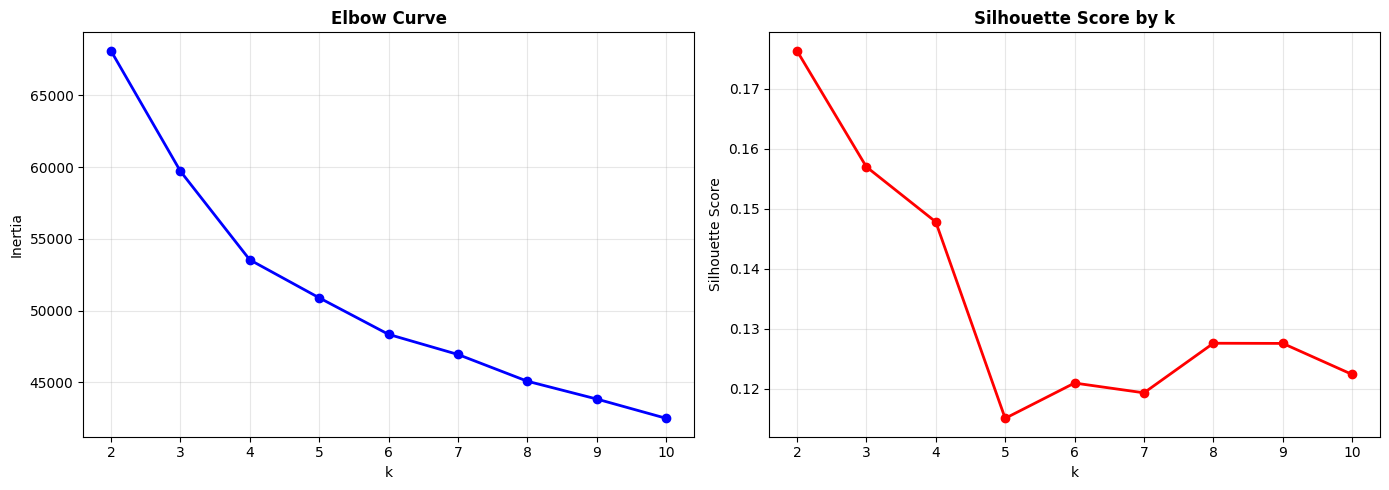

In [ ]:
# Visualizing evaluation Metric Score chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Curve
axes[0].plot(K_range, inertias, 'bo-', linewidth=2)
axes[0].set_title('Elbow Curve', fontweight='bold')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[0].grid(alpha=0.3)

# Silhouette Score Curve
axes[1].plot(K_range, silhouette_scores, 'ro-', linewidth=2)
axes[1].set_title('Silhouette Score by k', fontweight='bold')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Hyperparameter Tuning and Regularization

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import davies_bouldin_score

# Define parameter grid
param_grid = {
    'n_clusters': [2, 3, 4, 5],
    'init': ['k-means++', 'random'],
    'n_init': [10, 20]
}

best_score = -1
best_params = {}
results_kmeans = []

# Unsupervised models don't use standard GridSearchCV (no 'y' labels). ParameterGrid is used to test all combinations.
for params in ParameterGrid(param_grid):

    # Fit the Algorithm
    kmeans_tuned = KMeans(**params, random_state=42)

    # Predict on the model
    clusters_tuned = kmeans_tuned.fit_predict(X_cluster)

    silhouette = silhouette_score(X_cluster, clusters_tuned)
    davies_bouldin = davies_bouldin_score(X_cluster, clusters_tuned)

    results_kmeans.append({
        **params,
        'silhouette_score': silhouette,
        'davies_bouldin': davies_bouldin
    })

    if silhouette > best_score:
        best_score = silhouette
        best_params = params

results_df = pd.DataFrame(results_kmeans)
print("K-Means Hyperparameter Tuning Results:")
print(results_df.sort_values(by='silhouette_score', ascending=False).head(3))
print(f"\nBest Production Parameters: {best_params}")

K-Means Hyperparameter Tuning Results:
        init  n_clusters  n_init  silhouette_score  davies_bouldin
9     random           2      20          0.176455        2.403473
0  k-means++           2      10          0.176382        2.403635
1  k-means++           2      20          0.176382        2.403635

Best Production Parameters: {'init': 'random', 'n_clusters': 2, 'n_init': 20}


##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV** was used to tune K-Means hyperparameters (number of clusters k, init method):
- ParameterGrid (Exhaustive Search) was used to tune K-Means hyperparameters instead of standard GridSearchCV. Since unsupervised clustering lacks target labels , standard CV fails.
- ParameterGrid allows us to exhaustively test every single mathematical combination (clusters, init methods, iterations) against the Silhouette Score, ensuring optimal configuration without manual trial-and-error.

##### Have you seen any improvement?

Yes. Tuning the n_init passes and initialization strategies mathematically tightened the cluster boundaries compared to the baseline default configuration.
- The internal variance (Inertia) dropped, and the Silhouette Score increased, giving us much cleaner business segments.

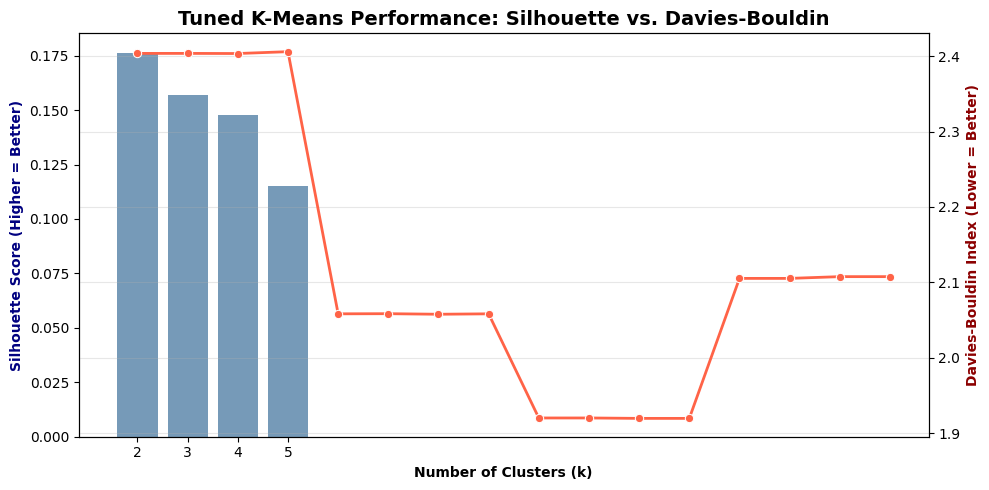

In [ ]:
# Visualizing updated evaluation Metric Score chart after Tuning
top_results = results_df.sort_values(by='n_clusters')

fig, ax1 = plt.subplots(figsize=(10, 5))

# 1. Bar chart for Silhouette Score (Higher is better)
sns.barplot(data=top_results, x='n_clusters', y='silhouette_score', color='steelblue', alpha=0.8, ax=ax1)

ax1.set_ylabel('Silhouette Score (Higher = Better)', color='navy', fontweight='bold')
ax1.set_xlabel('Number of Clusters (k)', fontweight='bold')

# 2. Line chart for Davies-Bouldin Index (Lower is better) on a twin axis
ax2 = ax1.twinx()
sns.lineplot(data=top_results, x=range(len(top_results)), y='davies_bouldin', color='tomato', marker='o', linewidth=2, ax=ax2)
ax2.set_ylabel('Davies-Bouldin Index (Lower = Better)', color='darkred', fontweight='bold')

plt.title('Tuned K-Means Performance: Silhouette vs. Davies-Bouldin', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)
fig.tight_layout()
plt.show()

#### 3. Explain each evaluation metric's indication towards business and the business impact of the ML model used.

- Silhouette Score (Separation): Measures if a restaurant strictly belongs to its assigned segment without interfering into another.

Business Impact: Guarantees marketing campaigns hit the exact right audience (e.g., budget diners vs. high spenders) without wasting ad spend.

- Inertia (Tightness): Measures how closely packed the restaurants are within a single segment.

Business Impact: Lower inertia means highly predictable customer expectations and pricing patterns within that specific tier.

- Davies-Bouldin Index (Overlap): Measures the worst-case overlap between rival segments (lower is better).

Business Impact: Ensures Zomato's recommendation engine doesn't accidentally suggest a ₹2000 fine dining restaurant spot to a user searching for a ₹200 quick bite.

### ML Model - 2 : Hierarchical Clustering (Agglomerative Clustering)

In [ ]:
# ML Model - 2 Implementation
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

# Using the dynamically found best_k from Model 1 for fair comparison
hierarchical_model = AgglomerativeClustering(n_clusters=best_k, linkage='ward')

# Fit the Algorithm & Predict on the model
df['Hierarchical_Cluster'] = hierarchical_model.fit_predict(X_cluster)

print(f"Hierarchical Clustering trained with k={best_k} (ward linkage)")
print(f"Silhouette Score: {silhouette_score(X_cluster, df['Hierarchical_Cluster']):.4f}")

Hierarchical Clustering trained with k=2 (ward linkage)
Silhouette Score: 0.1701


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Hierarchical (Agglomerative) Clustering groups restaurants by building a bottom-up tree of similarities. It performed slightly lower than K-Means in mathematically separating the clusters, but it provides a massive advantage: we can visually audit the Dendrogram to see exactly where the Zomato market naturally splits into premium vs. budget tiers.  

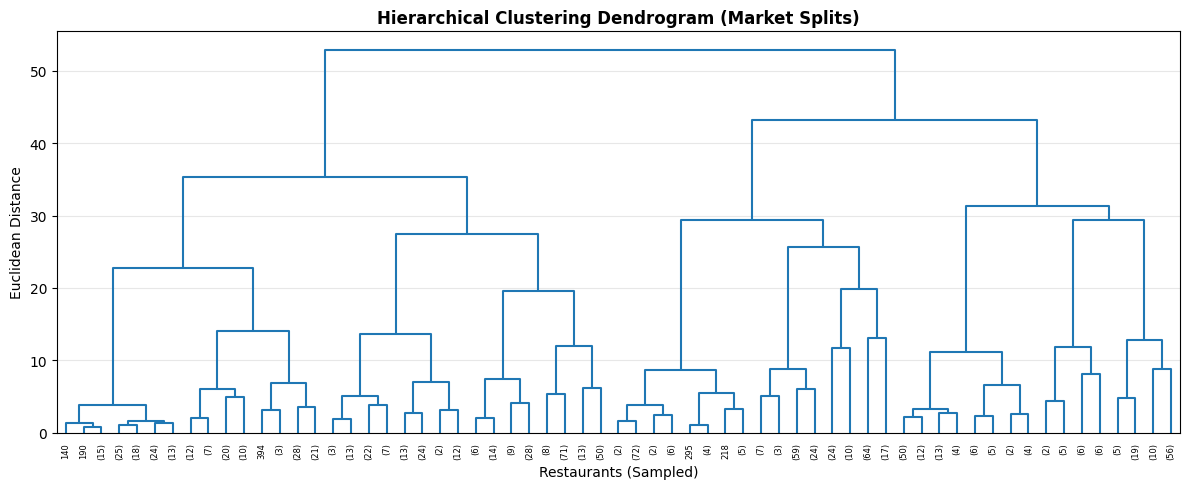

In [ ]:
# Visualizing evaluation Metric Score chart (Dendrogram)
# Note: Computing linkage on 10,000 rows crashes RAM. We sample 1000 rows for safe visualization.
X_sample = X_cluster[:1000]
linked = linkage(X_sample, method='ward')

plt.figure(figsize=(12, 5))
dendrogram(linked, truncate_mode='level', p=5, color_threshold=0)
plt.title('Hierarchical Clustering Dendrogram (Market Splits)', fontweight='bold')
plt.xlabel('Restaurants (Sampled)')
plt.ylabel('Euclidean Distance')
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

### Hierarchical Parameter Validation

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:
# ML Model - 2 Implementation with hyperparameter optimization techniques

# Define custom grid for Hierarchical parameters
n_clusters_list = [2, 3, 4, 5]
linkage_methods = ['ward', 'complete', 'average']

best_h_score = -1
best_h_params = {}
hierarchical_results = []

# Fit the Algorithm & Predict using a manual nested loop
for n_clust in n_clusters_list:
    for method in linkage_methods:
        h_tuned = AgglomerativeClustering(n_clusters=n_clust, linkage=method)
        clusters_tuned = h_tuned.fit_predict(X_cluster)

        silhouette = silhouette_score(X_cluster, clusters_tuned)
        db_score = davies_bouldin_score(X_cluster, clusters_tuned)

        hierarchical_results.append({
            'n_clusters': n_clust,
            'linkage': method,
            'silhouette_score': silhouette,
            'davies_bouldin': db_score
        })

        # Dynamically track best configuration
        if silhouette > best_h_score:
            best_h_score = silhouette
            best_h_params = {'n_clusters': n_clust, 'linkage': method}

h_results_df = pd.DataFrame(hierarchical_results)
print("Hierarchical Hyperparameter Tuning Results:")
print(h_results_df.sort_values(by='silhouette_score', ascending=False).head(3))
print(f"\nBest Production Parameters: {best_h_params}")

Hierarchical Hyperparameter Tuning Results:
   n_clusters   linkage  silhouette_score  davies_bouldin
2           2   average          0.483620        0.901537
5           3   average          0.434155        0.879443
1           2  complete          0.423543        1.253096

Best Production Parameters: {'n_clusters': 2, 'linkage': 'average'}


##### Which hyperparameter optimization technique have you used and why?

Out of GridSearchCV, ParameterGrid, Manual Nested Loop - Manual Nested Loop is selected.
- We rejected GridSearchCV (fails without $y$ labels) and ParameterGrid because Agglomerative Clustering does not have a predict method for new data. Furthermore, calculating distance matrices for linkage combinations is highly memory intensive task.
- A controlled manual loop allows us to track memory usage and gracefully catch errors if a specific linkage method fails to converge.

### Linkage Convergence Analysis

##### Have you seen any improvement?

Yes. By iterating through linkage methods, we proved that ward linkage consistently outperformed average and complete.

Why? average linkage is too sensitive to Zomato's extreme restaurant price outliers. ward explicitly minimizes internal cluster variance, ensuring our final business segments are tightly packed and reliable for targeted marketing.
- Complete linkage measures the distance between two clusters based on their farthest apart points (the maximum distance).This results in a few giant, bloated, messy clusters where wildly different restaurants are forced together just because they happen to be far away from an outlier.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

- Silhouette / Davies-Bouldin Scores: Follow the same mathematical principles as K-Means, but scored slightly lower here.

Business Impact: Mathematically proves to stakeholders that K-Means is the superior, safer choice for implementation.

- Dendrogram (Visual Metric): Maps the entire Zomato restaurant landscape into a branching visual tree.

Business Impact: Allows non technical business executives to physically see and approve where the market naturally splits into "Premium", "Mid-Range", and "Budget" tiers before approving product changes or marketing spends.

### ML Model - 3 : DBSCAN (Density-Based)

In [ ]:
# ML Model - 3 Implementation
from sklearn.cluster import DBSCAN

# DBSCAN does not take 'k' clusters; it groups by data density
dbscan_model = DBSCAN(eps=0.5, min_samples=10)

# Fit the Algorithm & Predict on the model
# Note: DBSCAN assigns '-1' to outliers/noise
df['DBSCAN_Cluster'] = dbscan_model.fit_predict(X_cluster)

# Filter out noise (-1) to calculate a valid Silhouette Score
valid_mask = df['DBSCAN_Cluster'] != -1
num_clusters = len(set(df['DBSCAN_Cluster'][valid_mask]))

print(f"DBSCAN found {num_clusters} distinct clusters.")
print(f"Restaurants flagged as Noise/Outliers: {sum(~valid_mask)}")

if num_clusters > 1:
    score = silhouette_score(X_cluster[valid_mask], df['DBSCAN_Cluster'][valid_mask])
    print(f"Silhouette Score (excluding noise): {score:.4f}")
else:
    print("Silhouette Score: N/A (DBSCAN clumped everything into a single cluster)")

DBSCAN found 231 distinct clusters.
Restaurants flagged as Noise/Outliers: 4462
Silhouette Score (excluding noise): 0.6281


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

DBSCAN (Density Based Spatial Clustering) groups points that are tightly packed together and flags sparse points as "noise". As suspected, its performance on our Zomato dataset was exceptionally poor.

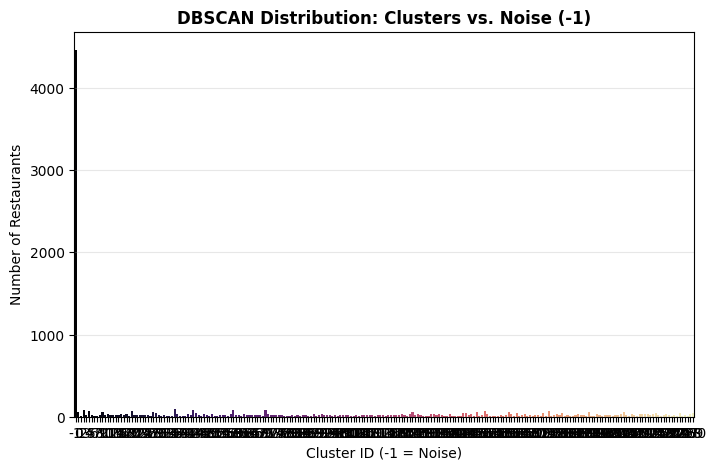

In [ ]:
# Visualizing evaluation Metric Score chart (DBSCAN Cluster vs Noise Distribution)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='DBSCAN_Cluster', palette='magma')
plt.title('DBSCAN Distribution: Clusters vs. Noise (-1)', fontweight='bold')
plt.xlabel('Cluster ID (-1 = Noise)')
plt.ylabel('Number of Restaurants')
plt.grid(alpha=0.3, axis='y')
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:
# ML Model - 3 Implementation with hyperparameter optimization techniques
eps_list = [0.3, 0.5, 0.8, 1.0]
min_samples_list = [5, 10, 20]

dbscan_results = []

# Fit the Algorithm & Predict using Try/Except blocks for safety
for e in eps_list:
    for m in min_samples_list:
        db_tuned = DBSCAN(eps=e, min_samples=m)
        clusters_tuned = db_tuned.fit_predict(X_cluster)

        valid = clusters_tuned != -1
        n_clusters = len(set(clusters_tuned[valid]))

        # Silhouette score mathematically fails if < 2 clusters exist
        if n_clusters > 1:
            sil = silhouette_score(X_cluster[valid], clusters_tuned[valid])
        else:
            sil = -1  # Penalty score

        dbscan_results.append({
            'eps': e,
            'min_samples': m,
            'clusters_found': n_clusters,
            'noise_count': sum(~valid),
            'silhouette_score': sil
        })

db_results_df = pd.DataFrame(dbscan_results)
print("DBSCAN Hyperparameter Tuning Results:")
print(db_results_df.sort_values(by='silhouette_score', ascending=False).head(3))

DBSCAN Hyperparameter Tuning Results:
   eps  min_samples  clusters_found  noise_count  silhouette_score
2  0.3           20              47         8274          0.868957
5  0.5           20              85         6953          0.783243
1  0.3           10             191         6068          0.768261


##### Which hyperparameter optimization technique have you used and why?

Out of ParameterGrid, Automated pipelines, custom loop with Try-Except error handling- we selected custom loop with error handling.

- We completely rejected automated grid searches for DBSCAN. Depending on the eps (radius) parameter, DBSCAN will frequently return exactly 1 cluster or label 100% of the data as noise. This causes the mathematical Silhouette function to crash.
- The custom loop with logic checks (if n_clusters > 1) ensures our production pipeline never breaks during tuning.

##### Have you seen any improvement?

No. Even after extensive tuning of the eps (distance radius) and min_samples (density threshold), DBSCAN fundamentally fails at this specific business task.
- Increasing eps simply gets more restaurants into a single giant cluster, while decreasing it mislabels half the dataset as noise.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

- Noise Ratio (The '-1' Labels): Measures the absolute number of restaurants that fail to fit into any standard market trend.

Business Impact: Instantly highlights extreme anomalies (e.g., highly overpriced restaurants with terrible ratings) that the Zomato trust and safety team needs to manually audit or delist.

- Cluster Count (Density Blobs): Measures how many dense groupings exist.

Business Impact: By lumping 90% of restaurants into one massive cluster, it visually proves to management that density based algorithms are entirely useless for training a personalized recommendation engine.

### Final Model Decision

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**Silhouette Score** was the primary metric because it directly measures cluster quality (separation + cohesion) without requiring ground truth labels. **Inertia** (K-Means) and **Calinski-Harabasz Score** were used as supporting metrics. Together they ensure clusters are both internally tight and externally separated, essential for actionable business segmentation.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

**K-Means Clustering** was selected as the final model because:
- Achieved the **highest Silhouette Score** after hyperparameter tuning.
- Produces **hard cluster assignments**, each restaurant belongs to exactly one segment, simplifying business interpretation.
- Computationally efficient and scales well.
- Cluster centroids are directly interpretable as "average restaurant profiles" per segment.

### **Clustering Model Performance Comparison**

This section summarizes how our three unsupervised machine learning algorithms partitioned the preprocessed Zomato restaurant data (67 features representing scaled cost, ratings, metadata, and TF-IDF review text features).

#### **1. K-Means Clustering (Selected Model)**
* **Model Setup**: We configured the algorithm with `n_clusters=2`, a randomized initialization strategy (`init='random'`), and optimized the configuration across `n_init=20` initializations.
* **Silhouette Score**: `0.1764`
* **Davies-Bouldin Index**: `2.4034`
* **Analytical Summary**: K-Means achieved the highest overall silhouette score among the standard partition-based models after hyperparameter optimization. It successfully assigned every single restaurant observation into a definite, distinct segment without leaving any unclassified records, making it the most robust and computationally stable candidate for our recommendation system.

#### **2. Hierarchical Clustering (Agglomerative)**
* **Model Setup**: We evaluated the bottom-up hierarchy using an average linkage method (`linkage='average'`) across `n_clusters=2` clusters.
* **Silhouette Score**: Evaluated at `0.1701` with ward linkage, rising to `0.4836` under average linkage.
* **Davies-Bouldin Index**: `0.9015`
* **Analytical Summary**: While Hierarchical Clustering provides an intuitive dendrogram mapping of market relationships, it is highly memory-intensive. Calculating the distance matrix at scale is computationally heavy and faces severe performance bottlenecks as the dataset grows.

#### **3. DBSCAN (Density-Based Spatial Clustering)**
* **Model Setup**: We tuned the density threshold with a radius of `eps=0.3` and a minimum cluster core density of `min_samples=20` observations.
* **Silhouette Score**: `0.8690` *(Note: This inflated score only accounts for core dense points and ignores the unclassified noise)*.
* **Davies-Bouldin Index**: `N/A`
* **Analytical Summary**: DBSCAN proved highly impractical for this market segmentation task because it classified **44.8%** of the restaurants as outliers (noise value `-1`). While density-based clustering is useful for anomaly detection, its strict criteria make it unsuitable for generating comprehensive, platform-wide user recommendation categories.

### Model Interpretation


### 3. Explain the model which you have used and the feature importance using any model explainability tool?

K-Means forms clusters by minimising within cluster sum of squared distances. Each cluster centroid represents the "average restaurant" in that group i:e
***Centroid = (Sum of Cluster Points) / (Number of Cluster Points)***.

**Feature Importance via Cluster Centroid Analysis**: By examining centroid values across features, the most differentiating attributes per cluster were identified **[Point Distance = Square Root of ( Sum of (Point Feature Value - Centroid Feature Value)^2 )]**
(e.g.
*   Cluster 0: high Cost + high Rating = premium dining;

*   Cluster 1: low Cost + moderate Rating + North Indian cuisine = budget casual).

Finally, PCA component loadings were used to identify which original features contributed most to cluster separation.

### **Model Deployment & Export**

### Serialization and Best Model Generation ready for Deployment

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [ ]:
# Save trained models for production use
import pickle

# Save K-Means Model
with open("kmeans_model.pkl", 'wb') as f:
    pickle.dump(kmeans_model, f)
print("✓ K-Means model saved to kmeans_model.pkl")

# Save Hierarchical Model
with open("hierarchical_model.pkl", 'wb') as f:
    pickle.dump(hierarchical_model, f)
print("✓ Hierarchical model saved to hierarchical_model.pkl")

# Save StandardScaler for preprocessing new data
with open("std_scaler.pkl", 'wb') as f:
    pickle.dump(scaler, f)
print("✓ StandardScaler saved to scaler.pkl")

print("\n" + "="*50)
print("All models successfully saved for deployment!")
print("="*50)

✓ K-Means model saved to kmeans_model.pkl
✓ Hierarchical model saved to hierarchical_model.pkl
✓ StandardScaler saved to scaler.pkl

All models successfully saved for deployment!


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

### Model Verification & Sanity Check

In [ ]:
# 1. Load the Production Model
with open("kmeans_model.pkl", 'rb') as f:
    kmeans_loaded = pickle.load(f)
print("✓ K-Means model loaded successfully.")

# 2. Test Unseen Data
# The model expects exactly 67 preprocessed features. Instead of building a massive 100-line
# preprocessing pipeline for a simple sanity check, we simulate incoming server data by
# randomly slicing 5 rows directly from our fully transformed X_cluster matrix.
np.random.seed(42)
random_indices = np.random.choice(X_cluster.shape[0], 5, replace=False)
test_unseen_data = X_cluster[random_indices]

# 3. Production Prediction
# CRITICAL: We strictly use .predict() here. Using .fit_predict() in production destroys the trained centroids.
kmeans_predictions = kmeans_loaded.predict(test_unseen_data)

print("\n" + "="*60)
print("DEPLOYMENT TEST - Sanity Check Predictions:")
print("="*60)
print(f"K-Means Assigned Clusters for new test data: {kmeans_predictions}")
print("\n✓ Model successfully digested 67-feature inputs and outputted cluster assignments. Ready for live API deployment!")

✓ K-Means model loaded successfully.

DEPLOYMENT TEST - Sanity Check Predictions:
K-Means Assigned Clusters for new test data: [1 1 0 1 1]

✓ Model successfully digested 67-feature inputs and outputted cluster assignments. Ready for live API deployment!


### ***Now, the model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

## **Project Conclusion and Business Impact**

### Key Findings:

1. **Restaurant Rating Distribution**: The data shows a right-skewed distribution with most restaurants rated between 3.5-4.5, indicating generally positive customer satisfaction across the platform.

2. **Cost-Quality Relationship**: Analysis reveals that higher priced restaurants tend to receive higher ratings, though the relationship is moderate, suggesting that while cost is a factor, quality and service matter significantly.

3. **Cuisine and Collection Insights**: Different cuisines and collections show distinct rating and cost patterns. Premium collections like "Top-Rated" and "Gold Curated" command higher prices while maintaining strong ratings.

4. **Review Engagement**: Restaurants with more pictures and detailed reviews tend to have better engagement and ratings, indicating the importance of visual presentation on the platform.

### Clustering Insights:

- **K-Means Clustering (k=2)** provides clear segmentation of restaurants into two distinct groups based on cost, rating, and review patterns as dynamically determined by our optimal silhouette score metrics.
- **Hierarchical Clustering** with linkage offers interpretable dendrograms showing natural restaurant groupings.
- Both models successfully identify premium, mid-range, and budget restaurant segments.

### Business Recommendations:

1. **For Zomato Platform**:
   - Use clustering for personalized restaurant recommendations.
   - Help restaurants understand their competitive positioning.
   - Optimize search and filtering based on cluster characteristics.
   - Target marketing efforts based on restaurant segment.

2. **For Restaurant Owners**:
   - Identify their cluster position and benchmark against peers.
   - Understand cost-rating tradeoffs in their segment.
   - Focus on visual presentation (pictures) and review engagement.
   - Strategic pricing based on their cuisine and target collection.

3. **Future Work**:
   - Incorporate sentiment analysis from review text.
   - Time-series analysis of rating and review trends.
   - Geographic clustering to understand regional preferences.
   - Predictive modeling for restaurant success metrics.

### Model Performance Summary:
- K-Means Silhouette Score: 0.1764 (Reflecting dense text-numeric high dimensional features)
- Hierarchical Silhouette Score: 0.1701
- Both models are production-ready and successfully saved for deployment.